# Per-candidate features on the adopted A3 search's top 300 (`mo_pad61` + floor clip + border band), 49 ROIs x 6 clicks

**What this notebook is.** The run of `CANDIDATE_FEATURE_EXTRACTION_PROMPT_V2.md` (the spec; repo root). For each of the
294 recorded `mo_pad61` clicks it takes the first 300 post-NMS rows of a deep A3 search (the floor clip at `b_otsu`, the
30 px border band invalid and floored, no peak cap), refines every candidate with the verbatim `refine_template_box` on
the unclipped channel, and measures 24 features and 9 diagnostics on it. It then checks, descriptively, whether each
feature measures what it claims (synthetic suites, a within-click validity report, montages).

**What it is not.** No ranking arm, combination, selection rule or verdict (spec Sections 0 and 10).

**Order of work** (spec Section 9): the synthetic suites and unit tests; the frozen `directions.csv`; the smoke run
(`CANDREFINE_SMOKE_ROIS=337.tiff,509.tiff,201.tiff,211.tiff`), then the full run; the gates; the validity report; the
montages. The last markdown cell holds the verdicts, written after the full run.

**Code layout.** The spawn workers cannot unpickle functions defined in a notebook cell, so the feature code, the deep
search glue and the per-ROI task live in `candidate_features_a3_top300_worker.py`, next to this notebook (the Stage A
pattern). That module extracts the verbatim code from the three source notebooks with `ast` at import time; nothing
copied is retyped. The synthetic suites below call the same functions the real-data run calls.

**In-sample.** Every real-data number here is in-sample on the 49 ROIs the pipeline was developed on, and the five
spike columns (`chr_concavities_per_um`, `chr_solidity`, `chr_radial_hf`, `chr_tophat_edge`,
`dark_concavities_per_um`) were measured on the recorded A3 pool on 2026-10-09, before `directions.csv` was frozen
(spec Section 2). Their `validity.csv` rows are not tests of the hypothesis.

In [1]:
import gc
import hashlib
import json
import os
import sys
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
from multiprocessing import get_context

import cv2
import numpy as np
import pandas as pd
import scipy.ndimage as ndi
from IPython.display import Image, display
from skimage.color import rgb2hed, rgb_from_hed
from skimage.filters import threshold_multiotsu

sys.path.insert(0, '../..')
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import production as prod

import candidate_features_a3_top300_worker as W

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 120)
NB_T0 = time.time()

SMOKE_ROIS = [s for s in os.environ.get('CANDREFINE_SMOKE_ROIS', '').split(',') if s] or None
SUFFIX = '' if SMOKE_ROIS is None else '_smoke'
REPO = '../..'
SUBSET_DIRS = {'original_14': f'{REPO}/images/extra_valid', 'testing_35': f'{REPO}/images/extra_valid/testing_set'}
DB_PATH = f'{REPO}/databases/MIDOG++.json'
INPUTS = {'clicks_per_run': f'{REPO}/results/tm_border_floor_49roi_6seed_per_run.csv', 'a3_per_run': f'{REPO}/results/tm_floor_definition_49roi_6seed_per_run.csv', 'a3_pool': f'{REPO}/results/tm_floor_definition_49roi_6seed_pool.csv.gz', 'gate_c_pool': f'{REPO}/results/candrefine_rerank_mo_pad61_select_pool.csv', 'midog_json': DB_PATH, 'manifest_14': f'{REPO}/images/extra_valid/MANIFEST.md', 'manifest_35': f'{REPO}/images/extra_valid/testing_set/MANIFEST.md', 'worker': 'candidate_features_a3_top300_worker.py', 'spec': f'{REPO}/CANDIDATE_FEATURE_EXTRACTION_PROMPT_V2.md'}
OUT_STEM = f'{REPO}/results/candidate_features_a3_top300{SUFFIX}'
OUT = {name: f'{OUT_STEM}_{name}.csv' for name in ('candidates', 'clicks', 'directions', 'validity', 'validity_depth300', 'redundancy', 'synthetic_tests', 'adversarial_log')}
OUT['spec_json'] = f'data/candidate_features_spec{SUFFIX}.json'
assert not set(map(os.path.abspath, OUT.values())) & set(map(os.path.abspath, INPUTS.values())), 'an output path would overwrite an input'
if SMOKE_ROIS is None:
    existing = [p for p in OUT.values() if os.path.exists(p)]
    assert not existing, f'the full run never overwrites its outputs; these already exist: {existing}'
VIEW_DIR = os.environ.get('CANDFEAT_VIEW_DIR', os.environ.get('TMPDIR', '/tmp'))   # temporary montage copies for the agent's own look; never inside the repo
assert not os.path.abspath(VIEW_DIR).startswith(os.path.abspath(REPO)), 'montage copies must not be written into the repo'

ROI_GROUP_FAILING = ('211', '242', '524', '546', '462', '527', '410', '245', '289')
MONTAGE_ROIS = ('300', '201', '013', '529', '425', '211', '546', '524')
MONTAGE_ROIS_PIGMENT = {'chr_resid_frac': ('211', '289', '339'), 'brown_frac_surround': ('291', '410', '123')}
PIGMENT_CHECK_ROIS = ('211', '289', '339')
NBR_CHECK_ROIS = ('245', '462')
NBR_CHECK_N = 10
NBR_CHECK_SEED = 20261009
SCANNER_MAP = {'3D Histech': '3dhistech', 'Aperio CS2': 'aperio_cs2', 'Hamamatsu S360': 'hamamatsu_s360', 'Hamamatsu XR': 'hamamatsu_xr'}
TOL_FLOAT = 1e-4          # gate B and C float tolerance (Intel-recorded vs this Mac)
GATE_C_MAX_SHARE = 0.01   # gate C halts above this mismatch share
N_OD_STRATA = 5
N_AREA_STRATA = 3
HOLE_SPLIT = 0.3
CONSISTENT_ROI_SHARE = 2 / 3
CONSISTENT_DOMAINS = 5
TB_K = 10
TB_MIN_ROWS = 20
MONTAGE_K = 10
MONTAGE_SEP_UM = 7.5
UNBLINDED = ('chr_concavities_per_um', 'chr_solidity', 'chr_radial_hf', 'chr_tophat_edge', 'dark_concavities_per_um')

# the adversarial log: every defect found in the spec and every definition changed gets a row (spec Section 2)
ADV = {}


def adv(item, concern, test, result='', action=''):
    """
        Register one row of the adversarial log.

        item (str): a short key.
        concern (str): what could be wrong.
        test (str): how this run tests it.
        result (str): what the test found, when already known.
        action (str): what was done about it.

        Returns None.
    """
    ADV[item] = dict(item=item, concern=concern, test=test, result=result, action=action)


def adv_result(item, result, action):
    """
        Fill in one registered row's result and action.

        item (str): the key it was registered under.
        result (str): what the test found.
        action (str): what was done.

        Returns None.
    """
    assert item in ADV, f'{item} was never registered'
    ADV[item].update(result=result, action=action)


adv('unblinded_2026_10_09', 'On 2026-10-09, before directions.csv existed, chr_concavities_per_um, chr_solidity, chr_radial_hf, chr_tophat_edge and dark_concavities_per_um were measured on the recorded A3 pool, which is this run\'s primary validity population (accepted rows with in_recorded_pool). dark_concavities_per_um was added after that look, and the mask choice per column was informed by it; t_dark\'s 0.44x calibration used labelled mitosis locations.', 'none possible on the same rows: for these five, validity.csv is in-sample and direction_measured vs direction_hypothesis is not a test. validity_depth300.csv adds auc_wc_beyond_pool / auc_dark_beyond_pool on rows with in_recorded_pool False (ranks ~100-299), the only rows the look did not see', 'recorded before any real-data cell', 'stated wherever these five are reported (validity tables, findings document)')
adv('worker_module', 'The spec names only the notebook; spawn workers cannot unpickle notebook-defined functions.', 'the feature, search-glue and per-ROI code live in candidate_features_a3_top300_worker.py (an extra new file, as tm_floor_stress_stageA_worker.py did); it extracts every copied function and constant from the source notebooks with ast at import, so nothing copied is retyped; gate A checks the refinement SHA-1', 'module written for this run', 'logged; the synthetic suites call the same module functions as the real-data run')
adv('view_dir', 'The spec says to save temporary montage copies under $TMPDIR; the agent session requires its scratchpad.', 'VIEW_DIR = $CANDFEAT_VIEW_DIR (the session scratchpad) with $TMPDIR as fallback; asserted outside the repo', 'set at run time', 'figures are embedded in the notebook only; no image file is written into the repo')
adv('pair_anchor_tie', 'Section 5.2\'s pair anchor is the piece overlapping M_chr most, ties to the larger piece; a symmetric pair (the gap-centred synthetic detection) ties on both.', 'a third tie-break, the lower label, added; every pair column is symmetric in anchor and partner, so the choice cannot change a value', 'gap- and plate-centred detections agree on every pair test case', 'logged as a reading')
adv('dark_piece_rule', 'Section 5.2 applies the 30 px small-piece rule to "its own M_dark piece" without saying whether before or after hole filling (M_chr\'s rule says unfilled).', 'the rule is applied to the unfilled M_dark component, as for M_chr; dark_touches_window is NaN (reason nan_reason_dark) only when no component overlaps M_chr', 'reading fixed before the run; the pale-arm and debris checked values reproduce under it', 'logged as a reading')
adv('elongation_degenerate', 'chr_elongation divides by axis_minor_length, which is 0 for a one-pixel-wide line; the spec gives no NaN reason for it.', 'NaN when the minor axis is 0; the flags cell reports any NaN no reason column explains', '', '')
adv('matched_ann_id_convention', 'Section 5.1 lists matched_ann_id without saying what an unmatched row holds.', 'ev.bucket_detections\' own convention (-1), which the recorded A3 pool also uses and gate B compares against; matched_unanimous and matched_n_mitotic_votes are empty on those rows, as the spec says', 'recorded', 'logged as a reading')
adv('gate_b_classifier', 'Gate B\'s near-tie rule is stated in words ("a difference that a float shift below 1e-4 can explain"), with two examples. The first full run with only those two examples coded halted on one row: 242.tiff click 1, rank 91, the peak at (2279, 3772) here against (2280, 3772) recorded. This machine scores those two adjacent pixels 1.8007210 and 1.8007209 (1.2e-7 apart, one float32 ulp), so the Intel/M5 float shift moved the local maximum by one pixel; the score agrees within 1e-6, the bucket (unannotated) and matched_ann_id are equal, od differs by 2.4e-4 because its 51 px window moved one pixel, and the other 99 rows are exact. The 2026-10-08 machine move had predicted such flips on the deep-pool path. The prefix NMS cannot cause it: positions come from extract_peaks, which is unchanged.', 'classifier: exact when positions, order and labels match and floats are within 1e-4 at shared positions; near-tie when (a) the differing ranks hold the same positions with scores within 1e-4, (b) the 100th and 101st pre-NMS peak scores are within 1e-4, or (c, added after that halt as the spec\'s general rule) every differing row\'s peak sits on the adjacent pixel (Chebyshev <= 1) with score within 1e-4 and identical bucket and matched_ann_id, all other rows exact; od is not compared on a shifted row (reported); anything else halts', '', '')
print(f'smoke ROIs = {SMOKE_ROIS}; outputs (written at the end):', *OUT.values(), sep='\n  ')

smoke ROIs = None; outputs (written at the end):
  ../../results/candidate_features_a3_top300_candidates.csv
  ../../results/candidate_features_a3_top300_clicks.csv
  ../../results/candidate_features_a3_top300_directions.csv
  ../../results/candidate_features_a3_top300_validity.csv
  ../../results/candidate_features_a3_top300_validity_depth300.csv
  ../../results/candidate_features_a3_top300_redundancy.csv
  ../../results/candidate_features_a3_top300_synthetic_tests.csv
  ../../results/candidate_features_a3_top300_adversarial_log.csv
  data/candidate_features_spec.json


## The verbatim code and gate A

`candidate_features_a3_top300_worker` extracted at import time, with `ast`:
- `refine_template_box` from cell 3 of `multiotsu_template_refinement_14roi.ipynb`, and the cell-1 constants it reads;
- every `def` in cell 5 and `search_arm` from cell 11 of `tm_floor_definition_49roi_6seed.ipynb`, and the cell-1
  constants they read (plus `RANK_KEY`, which the loop glue ranks by);
- `refusal_class` and `resample_closed` from cell 8 of `candrefine_rerank_mo_pad61_select.ipynb`.

`search_arm_deep` is `search_arm`'s own source with its one `detect(` call renamed to `detect_deep(`; `detect_deep` is
the only new search code (spec Section 3.1). Gate A: the SHA-1 of the extracted refinement segment + `"\n"`.

In [2]:
def sha256_12(path):
    """
        The first 12 hex digits of a file's SHA-256, so the inputs this notebook read are on record.

        path (str): the file to hash.

        Returns str: 12 hex characters.
    """
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()[:12]


INPUT_SHA = {name: sha256_12(p) for name, p in INPUTS.items()}
for name, p in INPUTS.items():
    print(f'  {INPUT_SHA[name]}  {p}')

# gate A: the refinement is the one at c767898
assert W.REFINE_SHA1 == '21c43a20db00dccf7ac3bab88aee423c345441b6', f'gate A: refine_template_box SHA-1 {W.REFINE_SHA1}'
print(f'\ngate A held: refine_template_box SHA-1 {W.REFINE_SHA1}')
print('refinement constants:', {k: v for k, v in W.REFINE_CONSTANTS.items()})
print('search defs exec\'d from cell 5 + cell 11:', W.SEARCH_DEF_NAMES)
print('search constants from cell 1:', list(W.SEARCH_CONSTANTS))
print('search_arm_deep = search_arm with one rename; the call line:', [ln.strip() for ln in W.SEARCH_ARM_DEEP_SRC.splitlines() if 'detect_deep(' in ln])
print(f'DEPTH = {W.DEPTH}, UNCAPPED = {W.UNCAPPED}, production MAX_PEAKS = {prod.MAX_PEAKS}')

  ef7940000fec  ../../results/tm_border_floor_49roi_6seed_per_run.csv
  704ebe6233b0  ../../results/tm_floor_definition_49roi_6seed_per_run.csv
  31ad036528e9  ../../results/tm_floor_definition_49roi_6seed_pool.csv.gz
  e5b38df77cc6  ../../results/candrefine_rerank_mo_pad61_select_pool.csv
  8c87ab4276eb  ../../databases/MIDOG++.json
  9c296ceecd2d  ../../images/extra_valid/MANIFEST.md
  c6955b02936e  ../../images/extra_valid/testing_set/MANIFEST.md
  8bfdd635d153  candidate_features_a3_top300_worker.py
  c2d34bc5df68  ../../CANDIDATE_FEATURE_EXTRACTION_PROMPT_V2.md

gate A held: refine_template_box SHA-1 21c43a20db00dccf7ac3bab88aee423c345441b6
refinement constants: {'WINDOW': 'WINDOW = tm.BASE_SIZE', 'CLASSES': 'CLASSES = 3', 'DILATE_KERNEL': 'DILATE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))', 'DILATE_ITERATIONS': 'DILATE_ITERATIONS = 1', 'MIN_PIECE_UM2': 'MIN_PIECE_UM2 = 1.0', 'MIN_BASE_UM': 'MIN_BASE_UM = 5.0', 'CLICK_RADIUS_UM': 'CLICK_RADIUS_UM = 3.75', 'MIN_A

## Synthetic suites and unit tests (spec Section 2, step 1; Section 5)

Every result goes into `synthetic_tests.csv`. A checked value counts as reproduced when it agrees to the precision the
spec prints (3 decimals unless stated); the observed value and the difference are stored either way. Where the spec
gives an ordering without a number ("clearly above", "far below", "low"), the criterion used is written into the
`criterion` column before the test runs; these criteria are this notebook's, not the spec's, and are logged.

`mpp` is 0.25 µm/px in every synthetic test (the spec's constructions state it, and the checked concavity values need it).

In [3]:
MPP_SYN = 0.25
SYN = []


def syn(suite, test, column, case, observed, expected=np.nan, tol=np.nan, passed=None, criterion='', mandatory=True, predicted_failure=False, note=''):
    """
        Record one synthetic result.

        suite (str): the spec suite.
        test (str): the check within it.
        column (str): the column it names.
        case (str): the shape and parameters.
        observed (float): the measured value.
        expected (float): the spec's checked value, NaN when there is none.
        tol (float): the agreement tolerance for a checked value.
        passed (bool or None): the outcome; None for a report-only row; computed from expected and tol when None and a checked value exists.
        criterion (str): the rule the outcome was judged by.
        mandatory (bool): whether the spec makes this test mandatory.
        predicted_failure (bool): whether the spec predicts this failure in advance.
        note (str): anything else.

        Returns None.
    """
    obs = float(observed) if observed is not None and not isinstance(observed, str) else np.nan
    if passed is None and np.isfinite(expected):
        passed = bool(abs(obs - expected) <= tol + 1e-12) if np.isfinite(obs) else False
        criterion = criterion or f'|observed - checked| <= {tol:g}'
    SYN.append(dict(suite=suite, test=test, column=column, case=case, observed=obs, expected=expected, delta=obs - expected if np.isfinite(expected) else np.nan, tol=tol, passed=passed, criterion=criterion, mandatory=mandatory, predicted_failure=predicted_failure, note=note))


def centred(n):
    """
        Centred pixel coordinates of an n x n canvas.

        n (int): the canvas side.

        Returns tuple[np.ndarray, np.ndarray]: x (column - n // 2) and y (row - n // 2).
    """
    c = n // 2
    y, x = np.mgrid[0:n, 0:n].astype(np.float64)
    return x - c, y - c


def rot(x, y, a):
    """
        Coordinates rotated by an angle: the along-ray t and across-ray o for a ray at angle a.

        x (np.ndarray): x coordinates.
        y (np.ndarray): y coordinates.
        a (float): the angle in radians.

        Returns tuple[np.ndarray, np.ndarray]: t = x cos a + y sin a, o = -x sin a + y cos a.
    """
    return x * np.cos(a) + y * np.sin(a), -x * np.sin(a) + y * np.cos(a)


def rays(x, y, angles, t_lo, t_hi, half_w):
    """
        The union of rectangles along rays: t_lo <= t <= t_hi and |o| <= half_w for each angle.

        x (np.ndarray): x coordinates.
        y (np.ndarray): y coordinates.
        angles (array-like): ray angles in radians.
        t_lo (float or array-like): the inner end, per ray when an array.
        t_hi (float or array-like): the outer end, per ray when an array.
        half_w (float): half the width; |o| <= w / 2 draws w + 1 px on axis-aligned rays.

        Returns np.ndarray: the boolean mask.
    """
    m = np.zeros(x.shape, bool)
    for i, a in enumerate(angles):
        t, o = rot(x, y, a)
        lo = t_lo[i] if np.ndim(t_lo) else t_lo
        hi = t_hi[i] if np.ndim(t_hi) else t_hi
        m |= (t >= lo) & (t <= hi) & (np.abs(o) <= half_w)
    return m


def ellipse_mask(x, y, a, b):
    """
        An axis-aligned ellipse.

        x (np.ndarray): x coordinates.
        y (np.ndarray): y coordinates.
        a (float): the semi-axis along x.
        b (float): the semi-axis along y.

        Returns np.ndarray: the boolean mask.
    """
    return (x / a) ** 2 + (y / b) ** 2 <= 1


def outline_shapes(r):
    """
        Section 5.2's outline-suite shapes at radius r, centred on a (6r + 1)^2 canvas.

        r (int): the radius in px.

        Returns dict: name -> boolean mask (the mask is M_chr).
    """
    x, y = centred(6 * r + 1)
    rho, th = np.hypot(x, y), np.arctan2(y, x)
    s = {'disc': rho <= r, 'ellipse 2:1': ellipse_mask(x, y, r * np.sqrt(2), r / np.sqrt(2)), 'ellipse 4:1': ellipse_mask(x, y, 2 * r, r / 2)}
    for k in (5, 8, 12):
        s[f'star {k}'] = rho <= r * (1 + 0.25 * np.cos(k * th))
    a, b = r * np.sqrt(2), r / np.sqrt(2)
    phis = 2 * np.pi * np.arange(12) / 12
    e = 1.0 / np.sqrt(np.cos(phis) ** 2 / a ** 2 + np.sin(phis) ** 2 / b ** 2)
    s['spiked ellipse'] = s['ellipse 2:1'] | rays(x, y, phis, e - 1, e + 4, 1)
    s['touching discs'] = (np.hypot(x - 0.9 * r, y) <= 0.9 * r) | (np.hypot(x + 0.9 * r, y) <= 0.9 * r)
    s['notched disc'] = (rho <= r) & ~((x >= 0) & (np.abs(y) <= max(1, r / 8)))
    return s


print('synthetic helpers defined')

synthetic helpers defined


In [4]:
# ---- Section 5.2: the outline suite on ideal masks (M_chr handed in directly)
OUTLINE_CHECKED = {'disc': ((0.057, 0.010), (0.000, 0.000), (0.925, 0.961)), 'ellipse 2:1': ((0.033, 0.008), (0.000, 0.000), (0.981, 0.971)), 'ellipse 4:1': ((0.097, 0.081), (0.000, 0.000), (0.873, 0.938)), 'star 5': ((0.024, 0.020), (0.303, 0.146), (0.790, 0.803)), 'star 8': ((2.328, 1.681), (0.343, 0.183), (0.663, 0.708)), 'star 12': ((1.089, 1.635), (0.470, 0.205), (0.738, 0.680)), 'spiked ellipse': ((1.346, 0.453), (0.350, 0.252), (0.692, 0.753)), 'touching discs': ((0.180, 0.158), (0.088, 0.043), (0.831, 0.861)), 'notched disc': ((0.075, 0.035), (0.060, 0.030), (0.819, 0.869))}
OUTLINE_COLS = ('chr_radial_hf', 'chr_concavities_per_um', 'chr_solidity')
OUT_V = {}
for ri, r in enumerate((8, 16)):
    for name, m in outline_shapes(r).items():
        g = W.geometry_cols(m, MPP_SYN)
        OUT_V[(name, r)] = g
        for ci, col in enumerate(OUTLINE_COLS):
            syn('5.2 outline suite', 'checked value', col, f'{name}, r={r}', g[col], OUTLINE_CHECKED[name][ci][ri], 0.0005)
        syn('5.2 outline suite', 'value (report)', 'chr_elongation', f'{name}, r={r}', g['chr_elongation'], mandatory=False)

SMOOTH, SPIKY, LOBED = ('disc', 'ellipse 2:1', 'ellipse 4:1'), ('star 8', 'star 12', 'spiked ellipse'), ('touching discs', 'notched disc')
for r in (8, 16):
    for col, sign in (('chr_radial_hf', 1), ('chr_concavities_per_um', 1), ('chr_solidity', -1)):
        ok = all(sign * OUT_V[(s, r)][col] > sign * OUT_V[(m, r)][col] for s in SPIKY for m in SMOOTH)
        worst = min(sign * (OUT_V[(s, r)][col] - OUT_V[(m, r)][col]) for s in SPIKY for m in SMOOTH)
        syn('5.2 outline suite', 'spikes beyond smooth shapes', col, f'r={r}', worst, passed=ok, criterion=f'every spiked shape {">" if sign > 0 else "<"} every disc/ellipse; observed = smallest margin in the spike direction')
        ok = all(sign * OUT_V[(s, r)][col] > sign * OUT_V[(m, r)][col] for s in SPIKY for m in LOBED)
        worst = min(sign * (OUT_V[(s, r)][col] - OUT_V[(m, r)][col]) for s in SPIKY for m in LOBED)
        syn('5.2 outline suite', 'lobulation test', col, f'r={r}', worst, passed=ok, criterion=f'touching and notched discs {"<" if sign > 0 else ">"} the 8-, 12-lobed stars and the spiked ellipse; observed = smallest margin')
    e = [OUT_V[(s, r)]['chr_elongation'] for s in SMOOTH]
    syn('5.2 outline suite', 'elongation separates discs from ellipses', 'chr_elongation', f'r={r}', e[1] - e[0], passed=bool(e[0] < e[1] < e[2]), criterion='disc < 2:1 ellipse < 4:1 ellipse; observed = 2:1 minus disc')
for name in ('disc', 'ellipse 2:1', 'ellipse 4:1', 'star 5', 'star 8', 'star 12', 'touching discs', 'notched disc', 'spiked ellipse'):
    for col in OUTLINE_COLS:
        v8, v16 = OUT_V[(name, 8)][col], OUT_V[(name, 16)][col]
        rel = abs(v8 - v16) / max(abs(v8), abs(v16)) if max(abs(v8), abs(v16)) > 0 else 0.0
        exempt = col == 'chr_concavities_per_um' or name == 'spiked ellipse'
        syn('5.2 outline suite', 'scale rule', col, name, rel, passed=None if exempt else bool(rel <= 0.10), criterion='r = 8 and r = 16 agree within 10 % of the larger' + (' (exempt by the spec: ' + ('a count per µm' if col == 'chr_concavities_per_um' else 'fixed-size spikes') + ')' if exempt else ''), mandatory=not exempt, predicted_failure=col == 'chr_radial_hf' and not exempt)
sc = pd.DataFrame([s for s in SYN if s['test'] == 'scale rule' and s['mandatory']])
print('outline suite: checked values reproduced', sum(s['passed'] for s in SYN if s['suite'] == '5.2 outline suite' and s['test'] == 'checked value'), 'of', sum(1 for s in SYN if s['suite'] == '5.2 outline suite' and s['test'] == 'checked value'))
print(pd.DataFrame([s for s in SYN if s['test'] in ('spikes beyond smooth shapes', 'lobulation test', 'elongation separates discs from ellipses')])[['test', 'column', 'case', 'observed', 'passed']].to_string(index=False))
print('\nscale rule (relative difference r=8 vs r=16):')
print(sc.pivot_table(index='case', columns='column', values='observed').round(3).to_string())
print('scale-rule failures:', sc[~sc['passed'].astype(bool)].groupby('column').size().to_dict())

outline suite: checked values reproduced 54 of 54
                                    test                 column case  observed  passed
             spikes beyond smooth shapes          chr_radial_hf  r=8  0.991914    True
                         lobulation test          chr_radial_hf  r=8  0.908692    True
             spikes beyond smooth shapes chr_concavities_per_um  r=8  0.343146    True
                         lobulation test chr_concavities_per_um  r=8  0.255148    True
             spikes beyond smooth shapes           chr_solidity  r=8  0.135598    True
                         lobulation test           chr_solidity  r=8  0.081343    True
elongation separates discs from ellipses         chr_elongation  r=8  1.022899    True
             spikes beyond smooth shapes          chr_radial_hf r=16  0.371556    True
                         lobulation test          chr_radial_hf r=16  0.294844    True
             spikes beyond smooth shapes chr_concavities_per_um r=16  0.182653  

In [5]:
# ---- Section 5.2: the end-to-end C1 test through the verbatim refinement
T_DARK_E2E = 0.088   # fixed at 0.44 x the 0.20 OD body, not computed from the canvas (spec 5.2, step 6)


def e2e_canvas(shape, r=None, L=4, w=4, arm_frac=1.0, sigma=1.0, seed=0, rf=None, nf=None):
    """
        One end-to-end C1 canvas: cell disc, arms at the arm OD, body at 0.20 OD, blur, then noise, float32.

        shape (str): 'spiked', 'touching', 'disc' or 'debris'.
        r (int): the body radius in px.
        L (int): the arm length beyond the body.
        w (int): the arm width parameter (|o| <= w / 2).
        arm_frac (float): the arm OD as a share of the body's.
        sigma (float): the Gaussian blur in px.
        seed (int): the noise seed.
        rf (float): the debris fragment radius.
        nf (int): the number of debris fragments, the central one included.

        Returns tuple[np.ndarray, np.ndarray]: the canvas and the arm pixels (outside the body).
    """
    n = 201
    x, y = centred(n)
    img = np.full((n, n), 0.03)
    img[np.hypot(x, y) <= 30] = 0.045
    arms = np.zeros((n, n), bool)
    if shape == 'spiked':
        body = np.hypot(x, y) <= r
        arms = rays(x, y, 2 * np.pi * np.arange(8) / 8, r - 1, r + L, w / 2) & ~body
        img[arms] = 0.20 * arm_frac
    elif shape == 'touching':
        body = (np.hypot(x - 0.9 * r, y) <= 0.9 * r) | (np.hypot(x + 0.9 * r, y) <= 0.9 * r)
    elif shape == 'disc':
        body = np.hypot(x, y) <= r
    else:
        body = np.hypot(x, y) <= rf
        for k in range(nf - 1):
            d, a = 8 + 3 * (k % 2), 2 * np.pi * k / (nf - 1) + 0.3
            body |= np.hypot(x - d * np.cos(a), y - d * np.sin(a)) <= rf
    img[body] = 0.20
    img = ndi.gaussian_filter(img, sigma) + np.random.default_rng(seed).normal(0, 0.003, (n, n))
    return img.astype(np.float32), arms


def e2e_measure(img, arms):
    """
        The verbatim refinement at the canvas centre, then the outline and top-hat columns on its M_chr and M_dark.

        img (np.ndarray): the canvas.
        arms (np.ndarray): the arm pixels.

        Returns dict: mode, the five deciding columns, chr_tophat_core, and the share of arm pixels kept in M_chr.
    """
    ref = W.refine_template_box(img, 100, 100, MPP_SYN)
    assert ref['accepted'], ref['reason']
    m_chr = ref['selection_mask'] & (ref['class_map'] == 2)
    h_w = np.asarray(ref['hem_patch'], np.float32)
    g, d, th = W.geometry_cols(m_chr, MPP_SYN), W.dark_cols(h_w, m_chr, T_DARK_E2E, MPP_SYN), W.tophat_cols(h_w, m_chr, MPP_SYN)
    return dict(mode=ref['mode'], chr_radial_hf=g['chr_radial_hf'], chr_concavities_per_um=g['chr_concavities_per_um'], dark_concavities_per_um=d['dark_concavities_per_um'], chr_tophat_edge=th['chr_tophat_edge'], chr_solidity=g['chr_solidity'], chr_tophat_core=th['chr_tophat_core'], arm_px_in_mchr=float((arms[75:126, 75:126] & m_chr).sum() / arms.sum()) if arms.any() else np.nan)


E2E_COLS = ('chr_radial_hf', 'chr_concavities_per_um', 'dark_concavities_per_um', 'chr_tophat_edge', 'chr_solidity')
E2E_CHECKED = {(8, 'touching', None): (0.142, 0.097, 0.091, 0.015, 0.824), (8, 'spiked', 4): (1.446, 0.313, 0.299, 0.100, 0.747), (8, 'spiked', 8): (3.791, 0.189, 0.183, 0.136, 0.576), (12, 'touching', None): (0.136, 0.062, 0.060, 0.008, 0.870), (12, 'spiked', 4): (0.852, 0.260, 0.239, 0.058, 0.727), (12, 'spiked', 8): (2.406, 0.163, 0.157, 0.101, 0.526)}
E2E = {}
for seed in range(4):
    for r in (8, 12):
        E2E[(seed, r, 'touching', None)] = e2e_measure(*e2e_canvas('touching', r, seed=seed))
        for L in (4, 8):
            E2E[(seed, r, 'spiked', L)] = e2e_measure(*e2e_canvas('spiked', r, L=L, seed=seed))
for (r, shape, L), vals in E2E_CHECKED.items():
    for col, v in zip(E2E_COLS, vals):
        syn('5.2 end-to-end C1', 'checked value (deciding cell, seed 0)', col, f'{shape}, r={r}, L={L}', E2E[(0, r, shape, L)][col], v, 0.0005)
DECIDING = {}
for seed in range(4):
    for col in E2E_COLS:
        sign = -1 if col == 'chr_solidity' else 1
        for r in (8, 12):
            for L in (4, 8):
                s, t = E2E[(seed, r, 'spiked', L)][col], E2E[(seed, r, 'touching', None)][col]
                ok = bool(sign * s > sign * t)
                if seed == 0:
                    DECIDING[(col, r, L)] = ok
                syn('5.2 end-to-end C1', 'deciding cell' if seed == 0 else 'deciding cell, other seed (report)', col, f'r={r}, L={L}, w=4, arm 1.0x, sigma 1, seed {seed}', sign * (s - t), passed=ok, criterion='spiked ' + ('>' if sign > 0 else '<') + ' touching discs; observed = margin in the spike direction', mandatory=seed == 0)
print('deciding cell (seed 0): every column passes every (r, L):', all(DECIDING.values()))
print(pd.DataFrame([dict(seed=k[0], r=k[1], shape=k[2], L=k[3], **v) for k, v in E2E.items()]).round(3).to_string(index=False))

# the reporting cells: resolvability, never a direction
REPORT = []
for r in (8, 12):
    for L in (4, 8):
        for af in (0.7, 0.5):
            REPORT.append(dict(cell=f'arms {af}x', r=r, L=L, w=4, sigma=1.0, **e2e_measure(*e2e_canvas('spiked', r, L=L, arm_frac=af))))
        REPORT.append(dict(cell='w = 2', r=r, L=L, w=2, sigma=1.0, **e2e_measure(*e2e_canvas('spiked', r, L=L, w=2))))
        REPORT.append(dict(cell='sigma 1.5', r=r, L=L, w=4, sigma=1.5, **e2e_measure(*e2e_canvas('spiked', r, L=L, sigma=1.5))))
    REPORT.append(dict(cell='plain disc', r=r, L=np.nan, w=np.nan, sigma=1.0, **e2e_measure(*e2e_canvas('disc', r))))
for rf in (2.5, 3.0):
    REPORT.append(dict(cell=f'debris r_f {rf}, n_f 8', r=np.nan, L=np.nan, w=np.nan, sigma=1.0, **e2e_measure(*e2e_canvas('debris', rf=rf, nf=8))))
REPORT = pd.DataFrame(REPORT)
PALE_CHECKED = {(8, 4): ((0.075, 0.323), (0.000, 0.402)), (8, 8): ((0.075, 0.196), (0.000, 0.218)), (12, 4): ((0.000, 0.256), (0.000, 0.303)), (12, 8): ((0.052, 0.168), (0.000, 0.190))}
for (r, L), pair in PALE_CHECKED.items():
    for af, (vc, vd) in zip((0.7, 0.5), pair):
        row = REPORT[(REPORT['cell'] == f'arms {af}x') & (REPORT['r'] == r) & (REPORT['L'] == L)].iloc[0]
        syn('5.2 end-to-end C1', 'checked value (reporting cell)', 'chr_concavities_per_um', f'arms {af}x, r={r}, L={L}', row['chr_concavities_per_um'], vc, 0.0005)
        syn('5.2 end-to-end C1', 'checked value (reporting cell)', 'dark_concavities_per_um', f'arms {af}x, r={r}, L={L}', row['dark_concavities_per_um'], vd, 0.0005)
for rf, (vc, vd, vt) in ((2.5, (np.nan, 0.227, 0.330)), (3.0, (0.237, 0.203, 0.225))):
    row = REPORT[REPORT['cell'] == f'debris r_f {rf}, n_f 8'].iloc[0]
    if np.isnan(vc):
        syn('5.2 end-to-end C1', 'checked value (reporting cell)', 'chr_concavities_per_um', f'debris r_f {rf}', row['chr_concavities_per_um'], passed=bool(np.isnan(row['chr_concavities_per_um'])), criterion='NaN (largest piece < 30 px)')
    else:
        syn('5.2 end-to-end C1', 'checked value (reporting cell)', 'chr_concavities_per_um', f'debris r_f {rf}', row['chr_concavities_per_um'], vc, 0.0005)
    syn('5.2 end-to-end C1', 'checked value (reporting cell)', 'dark_concavities_per_um', f'debris r_f {rf}', row['dark_concavities_per_um'], vd, 0.0005)
    syn('5.2 end-to-end C1', 'checked value (reporting cell)', 'chr_tophat_edge', f'debris r_f {rf}', row['chr_tophat_edge'], vt, 0.0005)
for rr in REPORT.itertuples():
    for col in E2E_COLS + ('chr_tophat_core', 'arm_px_in_mchr'):
        syn('5.2 end-to-end C1', 'reporting cell (report)', col, f'{rr.cell}, r={rr.r}, L={rr.L}, w={rr.w}, sigma={rr.sigma}', getattr(rr, col), mandatory=False)
adv('debris_index', 'Section 5.2\'s debris cluster says "disc k sits at distance 8 + 3(k mod 2) and angle 2 pi k/(n_f - 1) + 0.3" without the range of k.', 'k = 0 .. n_f - 2 against k = 1 .. n_f - 1 on the checked debris values', 'k = 0 .. n_f - 2 reproduces 0.227 / 0.330 and 0.237 / 0.203 / 0.225; k = 1 .. n_f - 1 does not (it leaves r_f 2.5 NaN on M_dark)', 'k = 0 .. n_f - 2 used')
print('\nreporting cells (resolvability only):')
print(REPORT.round(3).to_string(index=False))

deciding cell (seed 0): every column passes every (r, L): True
 seed  r    shape   L mode  chr_radial_hf  chr_concavities_per_um  dark_concavities_per_um  chr_tophat_edge  chr_solidity  chr_tophat_core  arm_px_in_mchr
    0  8 touching NaN base          0.142                   0.097                    0.091            0.015         0.824            0.011             NaN
    0  8   spiked 4.0 base          1.446                   0.313                    0.299            0.100         0.747            0.014           0.820
    0  8   spiked 8.0 base          3.791                   0.189                    0.183            0.136         0.576            0.020           0.931
    0 12 touching NaN base          0.136                   0.062                    0.060            0.008         0.870            0.012             NaN
    0 12   spiked 4.0 base          0.852                   0.260                    0.239            0.058         0.727            0.012           0.582
    0 1

In [6]:
# ---- Section 5.2: the pair test, and Section 5.5: the membrane test (same canvas family)
N_PAIR = 201


def noisy_canvas(seed):
    """
        The pair/membrane canvas: 0.03 OD plus Gaussian noise of sigma 0.003; shapes are drawn over it, replacing the noise.

        seed (int): the noise seed.

        Returns np.ndarray: float64 canvas.
    """
    return 0.03 + np.random.default_rng(seed).normal(0, 0.003, (N_PAIR, N_PAIR))


def pair_canvas(sep_px, angle_deg, seed):
    """
        A synthetic anaphase window: cell disc, two 7 x 29 px plates sep_px apart along x' (rotated by angle_deg), blur sigma 1.

        sep_px (float): the centre-to-centre distance in px.
        angle_deg (float): the rotation about the canvas centre.
        seed (int): the noise seed.

        Returns np.ndarray: float32 canvas.
    """
    img = noisy_canvas(seed)
    x, y = centred(N_PAIR)
    img[np.hypot(x, y) <= 30] = 0.045
    xr, yr = rot(x, y, np.radians(angle_deg))
    for xk in (-sep_px / 2, sep_px / 2):
        img[(np.abs(xr - xk) <= 3) & (np.abs(yr) <= 14)] = 0.20
    return ndi.gaussian_filter(img, 1.0).astype(np.float32)


def membrane_canvas(kind, seed):
    """
        Section 5.5's membrane windows and Section 5.2's metaphase window, drawn over the noisy canvas, blur sigma 1.

        kind (str): 'vesicular', 'nucleolus', 'dark disc', 'clump' or 'metaphase'.
        seed (int): the noise seed.

        Returns np.ndarray: float32 canvas.
    """
    img = noisy_canvas(seed)
    x, y = centred(N_PAIR)
    rho = np.hypot(x, y)
    if kind in ('vesicular', 'nucleolus'):
        img[rho <= 24] = 0.07
        img[(rho > 22) & (rho <= 24)] = 0.16
        if kind == 'nucleolus':
            img[np.hypot(x - 3, y + 2) <= 4] = 0.16
    elif kind == 'dark disc':
        img[rho <= 18] = 0.17
    elif kind == 'clump':
        img[rho <= 20] = 0.07
        img[(rho > 18) & (rho <= 20)] = 0.15
        img[rho <= 8] = 0.20
    else:
        img[rho <= 34] = 0.045
        img[rho <= 22] = 0.02
        img[(np.abs(x) <= 4) & (np.abs(y) <= 16)] = 0.20
    return ndi.gaussian_filter(img, 1.0).astype(np.float32)


def canvas_measure(img, cx, cy):
    """
        The verbatim refinement at (cx, cy) on a canvas, then the pair, hole, ring and top-hat columns, with t_dark the canvas's upper 3-class multi-Otsu.

        img (np.ndarray): the canvas.
        cx (float): detection x.
        cy (float): detection y.

        Returns dict: accepted, reason, mode and the columns.
    """
    ref = W.refine_template_box(img, cx, cy, MPP_SYN)
    out = dict(accepted=ref['accepted'], reason=ref['reason'], mode=ref['mode'])
    if not ref['accepted']:
        return out
    m_chr = ref['selection_mask'] & (ref['class_map'] == 2)
    h_w = np.asarray(ref['hem_patch'], np.float32)
    t_dark = float(threshold_multiotsu(img, classes=3)[1])
    hem_101, _, (oy, ox) = W.window_101(img, cx, cy)
    m101 = np.zeros(hem_101.shape, bool)
    m101[oy:oy + 51, ox:ox + 51] = m_chr
    rings = W.ring_masks(m_chr, MPP_SYN)
    dk = W.darkness_cols(h_w, m_chr, rings)
    sc = W.surround_cols(h_w, np.full(h_w.shape, 128, np.uint8), np.zeros_like(h_w), np.zeros(h_w.shape, bool), rings, dk, 0.0, t_dark)
    out.update(W.pair_cols(hem_101, m101, MPP_SYN, t_dark), chr_hole_frac=W.geometry_cols(m_chr, MPP_SYN)['chr_hole_frac'], ring_peak_prominence=sc['ring_peak_prominence'], chr_tophat_edge=W.tophat_cols(h_w, m_chr, MPP_SYN)['chr_tophat_edge'], n_chr=int(m_chr.sum()))
    return out


PAIR_COLS = ('pair_sep_um', 'pair_area_ratio', 'pair_parallel_deg', 'pair_axis_deg')
PAIR_ROWS = []
for seed in range(4):
    for sep_um in (4.5, 7.0, 9.0):
        sep = sep_um / MPP_SYN
        for ang in (0, 30, 60, -30):
            img = pair_canvas(sep, ang, seed)
            a = np.radians(ang)
            gap, plate = canvas_measure(img, 100, 100), canvas_measure(img, 100 + sep / 2 * np.cos(a), 100 + sep / 2 * np.sin(a))
            PAIR_ROWS.append(dict(seed=seed, sep_um=sep_um, angle=ang, gap_accepted=gap['accepted'], gap_reason=gap['reason'], **{f'gap_{c}': gap.get(c, np.nan) for c in PAIR_COLS}, **{f'plate_{c}': plate.get(c, np.nan) for c in PAIR_COLS}, plate_reason_pair=plate.get('nan_reason_pair')))
            case = f'sep {sep_um} um, rotation {ang}, seed {seed}'
            if sep_um == 9.0:
                syn('5.2 pair test', 'gap-centred detection refused at 9 um (the refinement\'s own rule)', 'pair_sep_um', case, float(not gap['accepted']), passed=bool(not gap['accepted'] and gap['reason'].startswith('no piece centre within')), criterion='refused: no piece centre within 3.75 um', mandatory=False)
            else:
                for c, tol in zip(PAIR_COLS, (0.25, 0.05, 5.0, 5.0)):
                    syn('5.2 pair test', 'gap and plate centrings agree', c, case, abs(gap[c] - plate[c]), passed=bool(abs(gap[c] - plate[c]) <= tol), criterion=f'|gap - plate| <= {tol} (0.25 um, 5 deg; area ratio 0.05 is this notebook\'s)')
            for where, m in (('plate', plate),) + ((('gap', gap),) if sep_um != 9.0 else ()):
                if ang == 0:
                    for c, v, tol in zip(PAIR_COLS, (sep_um, 1.0, 0.0, 90.0), (0.05, 0.005, 0.5, 0.5)):
                        syn('5.2 pair test', 'checked value', c, f'{case}, {where}-centred', m[c], v, tol)
                else:
                    syn('5.2 pair test', 'oblique pair', 'pair_axis_deg', f'{case}, {where}-centred', m['pair_axis_deg'], passed=bool(m['pair_axis_deg'] >= 85), criterion='>= 85 deg')
                    syn('5.2 pair test', 'oblique pair', 'pair_parallel_deg', f'{case}, {where}-centred', m['pair_parallel_deg'], passed=bool(m['pair_parallel_deg'] <= 5), criterion='<= 5 deg')
                    syn('5.2 pair test', 'oblique pair (report)', 'pair_sep_um', f'{case}, {where}-centred', m['pair_sep_um'], mandatory=False)
PAIR_ROWS = pd.DataFrame(PAIR_ROWS)
print('pair test, every seed, rotation and centring:')
print(PAIR_ROWS.round(3).to_string(index=False))

MEMBRANE_CHECKED = {'vesicular': ('fallback', 0.06, 0.78), 'nucleolus': ('fallback', 0.00, 0.80), 'dark disc': ('base', 0.00, 0.00), 'clump': ('fallback', 0.15, 0.00)}
MEM_ROWS = []
for kind in ('vesicular', 'nucleolus', 'dark disc', 'clump', 'metaphase'):
    for seed in range(4):
        m = canvas_measure(membrane_canvas(kind, seed), 100, 100)
        MEM_ROWS.append(dict(kind=kind, seed=seed, **{k: m.get(k) for k in ('mode', 'n_chr', 'ring_peak_prominence', 'chr_hole_frac', 'chr_tophat_edge', 'nan_reason_pair')}))
        if kind != 'metaphase':
            if kind in ('nucleolus', 'dark disc'):
                syn('5.2 pair test', 'no partner', 'pair_sep_um', f'{kind}, seed {seed}', float(m['nan_reason_pair'] == 'no partner'), passed=bool(m['nan_reason_pair'] == 'no partner'), criterion='nan_reason_pair == no partner')
            mode, prom, hole = MEMBRANE_CHECKED[kind]
            syn('5.5 membrane test', 'refinement mode', 'ring_peak_prominence', f'{kind}, seed {seed}', float(m['mode'] == mode), passed=bool(m['mode'] == mode), criterion=f'mode == {mode}')
            syn('5.5 membrane test', 'checked value', 'ring_peak_prominence', f'{kind}, seed {seed}', m['ring_peak_prominence'], prom, 0.03)
            syn('5.5 membrane test', 'checked value', 'chr_hole_frac', f'{kind}, seed {seed}', m['chr_hole_frac'], hole, 0.03)
        else:
            syn('5.2 pair test', 'no partner', 'pair_sep_um', f'metaphase plate, seed {seed}', float(m['nan_reason_pair'] == 'no partner'), passed=bool(m['nan_reason_pair'] == 'no partner'), criterion='nan_reason_pair == no partner')
            syn('5.5 membrane test', 'metaphase plate in a clear zone (report)', 'ring_peak_prominence', f'seed {seed}', m['ring_peak_prominence'], mandatory=False, note='spec 5.5: 0.03')
        if kind == 'vesicular':
            syn('5.8 b top-hat suite', 'known confound: vesicular rim (report)', 'chr_tophat_edge', f'vesicular window, refined verbatim, seed {seed}', m['chr_tophat_edge'], mandatory=False, note='spec: 0.34, above the 2 px spikes (0.256)')
MEM_ROWS = pd.DataFrame(MEM_ROWS)
print('\nmembrane windows (and the metaphase window of the pair test):')
print(MEM_ROWS.round(3).to_string(index=False))

pair test, every seed, rotation and centring:
 seed  sep_um  angle  gap_accepted                                 gap_reason  gap_pair_sep_um  gap_pair_area_ratio  gap_pair_parallel_deg  gap_pair_axis_deg  plate_pair_sep_um  plate_pair_area_ratio  plate_pair_parallel_deg  plate_pair_axis_deg plate_reason_pair
    0     4.5      0          True                                   accepted            4.500                  1.0                    0.0             90.000              4.500                    1.0                      0.0               90.000                  
    0     4.5     30          True                                   accepted            4.497                  1.0                    0.0             89.570              4.497                    1.0                      0.0               89.570                  
    0     4.5     60          True                                   accepted            4.489                  1.0                    0.0             89.409     

In [7]:
# ---- Section 5.4: the texture noise test and the clipped-pixel test
def disc_canvas(n, r):
    """
        A centred disc mask on an n x n canvas.

        n (int): the canvas side.
        r (int): the radius in px.

        Returns tuple[np.ndarray, np.ndarray, np.ndarray]: x, y and the disc mask (x^2 + y^2 <= r^2).
    """
    x, y = centred(n)
    return x, y, x ** 2 + y ** 2 <= r ** 2


def granular_disc(n, r):
    """
        Section 5.8's granular disc: a 0.20 OD disc on 0.03 with +0.06 OD on a 2 px checkerboard more than 3 px inside the edge.

        n (int): the canvas side.
        r (int): the radius in px.

        Returns tuple[np.ndarray, np.ndarray]: the float32 image and the disc mask (M_chr).
    """
    x, y, d = disc_canvas(n, r)
    chk = (np.floor(x / 2) + np.floor(y / 2)) % 2 == 0
    img = np.where(d, 0.20, 0.03) + np.where((ndi.distance_transform_edt(d) > 3) & chk, 0.06, 0.0)
    return img.astype(np.float32), d


def lap_of(img, m, clipped=None):
    """
        h_chr_lap on a synthetic window with M_chr = m.

        img (np.ndarray): the H image.
        m (np.ndarray): the mask.
        clipped (np.ndarray or None): clipped pixels (none when None).

        Returns dict: h_chr_lap and nan_reason_texture.
    """
    clipped = np.zeros(m.shape, bool) if clipped is None else clipped
    return W.texture_cols(np.asarray(img, np.float32), m, clipped, MPP_SYN, float(np.asarray(img, np.float64)[m].mean()))


_, _, D71 = disc_canvas(71, 16)
flat = np.where(D71, 0.20, 0.03)
noisy = flat + np.random.default_rng(0).normal(0, 0.003, flat.shape)
NOISE = {'flat': lap_of(flat, D71)['h_chr_lap'], 'noisy': lap_of(noisy, D71)['h_chr_lap'], 'noisy blurred': lap_of(ndi.gaussian_filter(noisy, 1.0), D71)['h_chr_lap'], 'checkerboard': lap_of(granular_disc(71, 16)[0], D71)['h_chr_lap']}
for k, v, tol in (('flat', 0.00, 0.005), ('noisy', 1.07, 0.05), ('noisy blurred', 1.03, 0.05), ('checkerboard', 7.72, 0.005)):
    syn('5.4 noise test', 'checked value', 'h_chr_lap', f'{k}, noise seed 0', NOISE[k], v, tol, note='the noise draw is not pinned by the spec, so noisy values carry a 0.05 tolerance')
for k in ('flat', 'noisy', 'noisy blurred'):
    syn('5.4 noise test', 'far below the checkerboard', 'h_chr_lap', k, NOISE[k] / NOISE['checkerboard'], passed=bool(NOISE[k] <= 0.5 * NOISE['checkerboard']), criterion='<= 0.5 x the checkerboard (this notebook\'s reading of "far below"); observed = ratio')
print('noise test:', {k: round(v, 3) for k, v in NOISE.items()})

rgb = np.zeros((71, 71, 3), np.uint8)
rgb[:] = (230, 200, 220)
rgb[D71] = (40, 1, 100)
alt = rgb.copy()
idx = np.flatnonzero(D71.ravel())
pick = np.random.default_rng(0).choice(idx, size=int(round(0.07 * len(idx))), replace=False)
g = alt[:, :, 1].ravel().copy()
g[pick] = 0
alt[:, :, 1] = g.reshape(71, 71)
h0 = rgb2hed(rgb.astype(np.float32) / 255.0)[:, :, 0]
h1 = rgb2hed(alt.astype(np.float32) / 255.0)[:, :, 0]
clip1 = np.any((alt == 0) | (alt == 255), axis=2)
v0, v_ex, v_in = lap_of(h0, D71, np.any((rgb == 0) | (rgb == 255), axis=2))['h_chr_lap'], lap_of(h1, D71, clip1)['h_chr_lap'], lap_of(h1, D71)['h_chr_lap']
support = ndi.binary_erosion(D71) & ~ndi.binary_dilation(clip1, structure=np.ones((3, 3), bool))
syn('5.4 clipped-pixel test', 'excluded equals unaltered', 'h_chr_lap', f'{len(pick)} of {D71.sum()} disc px at G = 0, draw seed 0', v_ex - v0, passed=bool(abs(v_ex - v0) <= 1e-9), criterion='|excluded - unaltered| <= 1e-9')
syn('5.4 clipped-pixel test', 'checked value', 'h_chr_lap', 'unaltered disc', v0, 0.0, 0.005)
syn('5.4 clipped-pixel test', 'included value (report)', 'h_chr_lap', 'clipped pixels included', v_in, mandatory=False, note='spec, one implementation: 3.89; depends on the random draw')
syn('5.4 clipped-pixel test', 'support after exclusion (report)', 'h_chr_lap', 'support pixels', float(support.sum()), mandatory=False, note=f'eroded support {int(ndi.binary_erosion(D71).sum())} px; spec: 709 -> 383 for its draw')
print(f'clipped test: unaltered {v0:.3f}, excluded {v_ex:.3f}, included {v_in:.3f}; support {int(ndi.binary_erosion(D71).sum())} -> {int(support.sum())} px')
adv('clipped_test_draw', 'The clipped-pixel test\'s "random 7 %" has no pinned draw, so its included value (3.89) and support (709 -> 383) are draw-dependent.', 'draw seed 0', f'included {v_in:.2f}, support {int(ndi.binary_erosion(D71).sum())} -> {int(support.sum())}; the mandatory outcome (excluded == unaltered) holds', 'reported, not a failure')

noise test: {'flat': 0.0, 'noisy': 1.067, 'noisy blurred': 1.029, 'checkerboard': 7.72}
clipped test: unaltered 0.000, excluded 0.000, included 3.970; support 709 -> 368 px


In [8]:
# ---- Section 5.8 (a): the chr_resid_frac unit test
_h = rgb_from_hed[0] / np.linalg.norm(rgb_from_hed[0])
_e = rgb_from_hed[1] / np.linalg.norm(rgb_from_hed[1])
RESID_CASES = {'pure h': (0.8 * _h, 0.000, 0.001, (77, 70, 149)), '0.7h + 0.3e': (0.8 * (0.7 * _h + 0.3 * _e), 0.000, 0.000, (106, 60, 165)), 'neutral': (np.full(3, 0.6), 0.304, 0.304, (64, 64, 64)), 'brown': (0.9 * np.array([0.3, 0.5, 0.8]), 0.618, 0.615, (137, 90, 49))}
m11 = np.zeros((21, 21), bool)
m11[5:16, 5:16] = True
for k, (od, spec_v, checked_v, pix) in RESID_CASES.items():
    I = np.round(255 * 10 ** (-od)).astype(np.uint8)
    assert tuple(int(v) for v in I) == pix and ((I >= 20) & (I <= 235)).all(), f'{k}: rendered {I}, expected {pix}'
    v = W.resid_cols(np.broadcast_to(I, (21, 21, 3)).copy(), m11)['chr_resid_frac']
    syn('5.8 a resid unit test', 'expected value', 'chr_resid_frac', k, v, spec_v, 0.02)
    syn('5.8 a resid unit test', 'checked value', 'chr_resid_frac', k, v, checked_v, 0.0005)
nan_case = W.resid_cols(np.broadcast_to(np.array([10, 15, 5], np.uint8), (21, 21, 3)).copy(), m11)
syn('5.8 a resid unit test', 'every channel below 20 is NaN', 'chr_resid_frac', 'RGB (10, 15, 5)', nan_case['chr_resid_frac'], passed=bool(np.isnan(nan_case['chr_resid_frac']) and nan_case['nan_reason_resid'] == 'outside_20_235'), criterion='NaN, reason outside_20_235')
print('normal to the H-E plane:', np.round(W.RESID_NORMAL, 3))
print(pd.DataFrame([s for s in SYN if s['suite'] == '5.8 a resid unit test'])[['test', 'case', 'observed', 'expected', 'passed']].round(4).to_string(index=False))

# ---- Section 5.8 (b): the top-hat suite (whole canvas = H_w, M_chr = the unblurred shape)
def spike_canvas(n, r, w, sigma=0.0):
    """
        The 12-spike shape (disc plus 12 rays, r - 1 <= t <= r + 4, |o| <= w / 2) at 0.20 OD on 0.03, optionally blurred.

        n (int): the canvas side.
        r (int): the radius.
        w (int): the spike width parameter.
        sigma (float): the blur, 0 for none.

        Returns tuple[np.ndarray, np.ndarray]: the float32 image and the unblurred shape.
    """
    x, y, d = disc_canvas(n, r)
    s = d | rays(x, y, 2 * np.pi * np.arange(12) / 12, r - 1, r + 4, w / 2)
    img = np.where(s, 0.20, 0.03)
    return (ndi.gaussian_filter(img, sigma) if sigma else img).astype(np.float32), s


def bar_canvas(n, r, tips):
    """
        The about 4:1 bar |x| <= r/4, |y| <= r, optionally with six 2 px tip spikes at +-pi/2 + {-0.5, 0, 0.5}.

        n (int): the canvas side.
        r (int): the half length.
        tips (bool): add the tip spikes.

        Returns tuple[np.ndarray, np.ndarray]: the float32 image and the shape.
    """
    x, y = centred(n)
    b = (np.abs(x) <= r / 4) & (np.abs(y) <= r)
    if tips:
        b |= rays(x, y, [np.pi / 2 + o for o in (-0.5, 0, 0.5)] + [-np.pi / 2 + o for o in (-0.5, 0, 0.5)], r - 1, r + 4, 1)
    return np.where(b, 0.20, 0.03).astype(np.float32), b


TOPHAT_CHECKED = {'disc': ((0.035, 0.000), (0.000, 0.000)), '2 px spikes': ((0.256, 0.086), (0.000, 0.000)), '6 px lobes': ((0.014, 0.030), (0.000, 0.000)), '2 px spikes, sigma 1': ((0.118, 0.043), (0.001, 0.000)), 'granular disc': ((0.033, 0.000), (0.056, 0.092)), 'bar': ((0.120, 0.034), (0.000, 0.000)), 'tip-spiked bar': ((0.313, 0.146), (0.000, 0.000))}
TH = {}
for ri, (r, n) in enumerate(((8, 51), (16, 71))):
    _, _, d = disc_canvas(n, r)
    shapes = {'disc': (np.where(d, 0.20, 0.03).astype(np.float32), d), '2 px spikes': spike_canvas(n, r, 2), '6 px lobes': spike_canvas(n, r, 6), '2 px spikes, sigma 1': spike_canvas(n, r, 2, 1.0), 'granular disc': granular_disc(n, r), 'bar': bar_canvas(n, r, False), 'tip-spiked bar': bar_canvas(n, r, True)}
    for k, (img, m) in shapes.items():
        TH[(k, r)] = W.tophat_cols(img, m, MPP_SYN)
        for ci, col in enumerate(('chr_tophat_edge', 'chr_tophat_core')):
            syn('5.8 b top-hat suite', 'checked value', col, f'{k}, r={r}', TH[(k, r)][col], TOPHAT_CHECKED[k][ci][ri], 0.0005)
    e = {k: TH[(k, r)]['chr_tophat_edge'] for k in shapes}
    c = {k: TH[(k, r)]['chr_tophat_core'] for k in shapes}
    syn('5.8 b top-hat suite', 'disc low on both', 'chr_tophat_edge', f'r={r}', e['disc'], passed=bool(e['disc'] <= 0.05 and c['disc'] <= 0.05), criterion='disc edge and core <= 0.05 (this notebook\'s reading of "low")')
    syn('5.8 b top-hat suite', 'disc low on both', 'chr_tophat_core', f'r={r}', c['disc'], passed=bool(e['disc'] <= 0.05 and c['disc'] <= 0.05), criterion='disc edge and core <= 0.05')
    syn('5.8 b top-hat suite', '2 px spikes clearly above the disc', 'chr_tophat_edge', f'r={r}', e['2 px spikes'] - e['disc'], passed=bool(e['2 px spikes'] >= 2 * e['disc'] and e['2 px spikes'] - e['disc'] >= 0.03), criterion='>= 2 x and >= +0.03 (this notebook\'s reading of "clearly")')
    syn('5.8 b top-hat suite', '6 px lobes far below 2 px spikes', 'chr_tophat_edge', f'r={r}', e['6 px lobes'] / e['2 px spikes'], passed=bool(e['6 px lobes'] <= 0.5 * e['2 px spikes']), criterion='<= 0.5 x (this notebook\'s reading of "far below"); observed = ratio')
    syn('5.8 b top-hat suite', 'blur drop (report)', 'chr_tophat_edge', f'r={r}', 1 - e['2 px spikes, sigma 1'] / e['2 px spikes'], mandatory=False, note='share of the 2 px spike signal lost at sigma 1')
    syn('5.8 b top-hat suite', 'granular clearly above the disc on core', 'chr_tophat_core', f'r={r}', c['granular disc'] - c['disc'], passed=bool(c['granular disc'] - c['disc'] >= 0.03), criterion='>= +0.03 (this notebook\'s reading of "clearly")')
    syn('5.8 b top-hat suite', 'granular no more than 0.01 above the disc on edge', 'chr_tophat_edge', f'r={r}', e['granular disc'] - e['disc'], passed=bool(e['granular disc'] - e['disc'] <= 0.01), criterion='<= +0.01')
    syn('5.8 b top-hat suite', 'tip-spiked bar clearly above the bar', 'chr_tophat_edge', f'r={r}', e['tip-spiked bar'] - e['bar'], passed=bool(e['tip-spiked bar'] >= 2 * e['bar'] and e['tip-spiked bar'] - e['bar'] >= 0.03), criterion='>= 2 x and >= +0.03')
print('\ntop-hat suite (edge, core):', {f'{k} r={r}': (round(v['chr_tophat_edge'], 3), round(v['chr_tophat_core'], 3)) for (k, r), v in TH.items()})
adv('ordering_criteria', 'Several suites state an ordering without a number ("clearly above", "far below", "low").', 'criteria fixed in the code before the suites ran: clearly above = >= 2x and >= +0.03 (granular core: >= +0.03); far below = <= 0.5x; low = <= 0.05; pair area ratio agreement 0.05', 'every ordering also has the spec\'s checked values, which reproduce, so no outcome rests on the chosen thresholds alone', 'criteria stored per row in synthetic_tests.csv')

normal to the H-E plane: [-0.332 -0.081  0.94 ]
                         test            case  observed  expected  passed
               expected value          pure h    0.0014     0.000    True
                checked value          pure h    0.0014     0.001    True
               expected value     0.7h + 0.3e    0.0003     0.000    True
                checked value     0.7h + 0.3e    0.0003     0.000    True
               expected value         neutral    0.3041     0.304    True
                checked value         neutral    0.3041     0.304    True
               expected value           brown    0.6152     0.618    True
                checked value           brown    0.6152     0.615    True
every channel below 20 is NaN RGB (10, 15, 5)       NaN       NaN    True

top-hat suite (edge, core): {'disc r=8': (0.035, 0.0), '2 px spikes r=8': (0.256, 0.0), '6 px lobes r=8': (0.014, 0.0), '2 px spikes, sigma 1 r=8': (0.118, 0.001), 'granular disc r=8': (0.033, 0.056), 'bar r=8':

In [9]:
# ---- Section 5.8 (c): the edge-sharpness suite (diagnostic)
EDGE = {}
for r, n in ((8, 51), (16, 71)):
    x, y = centred(n)
    for name, m in (('disc', x ** 2 + y ** 2 <= r ** 2), ('ellipse 2:1', ellipse_mask(x, y, r * np.sqrt(2), r / np.sqrt(2)))):
        for s in (0, 1, 2):
            img = np.where(m, 0.20, 0.03)
            img = (ndi.gaussian_filter(img, s) if s else img).astype(np.float32)
            EDGE[(name, r, s)] = W.edge_col(img, m, MPP_SYN, W.darkness_cols(img, m, W.ring_masks(m, MPP_SYN)))['chr_edge_sharpness_per_um']
for r, vals in ((8, (1.93, 1.53, 1.16)), (16, (1.97, 1.47, 1.04))):
    for s, v in zip((0, 1, 2), vals):
        syn('5.8 c edge suite', 'checked value', 'chr_edge_sharpness_per_um', f'disc, r={r}, sigma={s}', EDGE[('disc', r, s)], v, 0.005)
        syn('5.8 c edge suite', 'ellipse within 6 % of the disc (checked)', 'chr_edge_sharpness_per_um', f'r={r}, sigma={s}', EDGE[('ellipse 2:1', r, s)] / EDGE[('disc', r, s)] - 1, passed=bool(abs(EDGE[('ellipse 2:1', r, s)] / EDGE[('disc', r, s)] - 1) <= 0.06), criterion='|ellipse / disc - 1| <= 0.06')
        syn('5.8 c edge suite', 'ellipse within 15 % of the disc', 'chr_edge_sharpness_per_um', f'r={r}, sigma={s}', EDGE[('ellipse 2:1', r, s)] / EDGE[('disc', r, s)] - 1, passed=bool(abs(EDGE[('ellipse 2:1', r, s)] / EDGE[('disc', r, s)] - 1) <= 0.15), criterion='|ellipse / disc - 1| <= 0.15')
    for name in ('disc', 'ellipse 2:1'):
        v = [EDGE[(name, r, s)] for s in (0, 1, 2)]
        syn('5.8 c edge suite', 'falls strictly with sigma', 'chr_edge_sharpness_per_um', f'{name}, r={r}', v[0] - v[2], passed=bool(v[0] > v[1] > v[2]), criterion='sigma 0 > 1 > 2')
for name in ('disc', 'ellipse 2:1'):
    for s in (0, 1, 2):
        a, b = EDGE[(name, 8, s)], EDGE[(name, 16, s)]
        syn('5.8 c edge suite', 'radii within 15 %', 'chr_edge_sharpness_per_um', f'{name}, sigma={s}', abs(a - b) / max(a, b), passed=bool(abs(a - b) / max(a, b) <= 0.15), criterion='|r8 - r16| / max <= 0.15')
print('edge sharpness:', {f'{k[0]} r={k[1]} s={k[2]}': round(v, 3) for k, v in EDGE.items()})

# ---- Section 5.8 (d): the neighbour unit test
xx = np.arange(101, dtype=float)[None, :].repeat(101, 0)
yy = xx.T
field = np.full((101, 101), 0.03, np.float32)
m_cand = np.zeros((101, 101), bool)
for xc in (24, 50, 76):
    for yc in (24, 50, 76):
        dsk = (xx - xc) ** 2 + (yy - yc) ** 2 <= 144
        field[dsk] = 0.15
        if (xc, yc) == (50, 50):
            m_cand = dsk
for xc, yc in ((100, 12), (12, 100)):
    field[(xx - xc) ** 2 + (yy - yc) ** 2 <= 144] = 0.15
lab, status = W.neighbour_components(field, m_cand, MPP_SYN, 0.09)
nb = W.neighbour_cols(field, m_cand, MPP_SYN, 0.09, float(m_cand.sum()) * MPP_SYN ** 2)
syn('5.8 d neighbour unit test', 'nbr_n = 8', 'nbr_n', '3 x 3 grid + 2 edge discs', nb['nbr_n'], 8, 0)
syn('5.8 d neighbour unit test', 'median 27.5625 um^2 exactly', 'nbr_nuc_area_med_um2', '3 x 3 grid + 2 edge discs', nb['nbr_nuc_area_med_um2'], 27.5625, 0)
syn('5.8 d neighbour unit test', 'ratio 1 (this notebook\'s addition: the candidate is a neighbour-sized disc)', 'chr_area_over_nbr', '3 x 3 grid + 2 edge discs', nb['chr_area_over_nbr'], 1.0, 0)
for col, key, v in (('spec_nbr_n', 'nbr_n', 8), ('spec_nbr_nuc_area_med_um2', 'nbr_nuc_area_med_um2', 27.5625), ('spec_chr_area_over_nbr', 'chr_area_over_nbr', 1.0)):
    syn('5.8 d neighbour unit test', 'same test, spec_ column (one function; only the threshold argument differs between the corrected and spec versions)', col, '3 x 3 grid + 2 edge discs', nb[key], v, 0)
print(f'neighbour unit test: {lab.max()} components, status {dict(pd.Series(status).value_counts())}; {nb}')

edge sharpness: {'disc r=8 s=0': 1.934, 'disc r=8 s=1': 1.532, 'disc r=8 s=2': 1.164, 'ellipse 2:1 r=8 s=0': 2.044, 'ellipse 2:1 r=8 s=1': 1.571, 'ellipse 2:1 r=8 s=2': 1.185, 'disc r=16 s=0': 1.967, 'disc r=16 s=1': 1.466, 'disc r=16 s=2': 1.042, 'ellipse 2:1 r=16 s=0': 1.992, 'ellipse 2:1 r=16 s=1': 1.473, 'ellipse 2:1 r=16 s=2': 1.05}
neighbour unit test: 11 components, status {'kept': 8, 'edge': 2, 'own': 1}; {'nbr_n': 8, 'nbr_nuc_area_med_um2': 27.5625, 'chr_area_over_nbr': 1.0, 'nan_reason_nbr': ''}


In [10]:
# ---- the synthetic table, and synthetic_pass per column (spec Section 6)
SYN_DF = pd.DataFrame(SYN)
mand = SYN_DF[SYN_DF['mandatory'] & SYN_DF['passed'].notna()]


def synthetic_pass(col):
    """
        A column's synthetic outcome: pass, fail (predicted), fail, or n.a.

        col (str): the column.

        Returns str: the outcome.
    """
    rows = mand[mand['column'] == col]
    if rows.empty:
        return 'n.a.'
    failed = rows[~rows['passed'].astype(bool)]
    if failed.empty:
        return 'pass'
    return 'fail (predicted)' if failed['predicted_failure'].all() else 'fail'


SYN_PASS = {c: synthetic_pass(c) for c in W.FEATURES + W.DIAGNOSTICS + W.SPEC_COLUMNS}
print(f'{len(SYN_DF)} synthetic rows; mandatory with an outcome: {len(mand)}; failed: {int((~mand["passed"].astype(bool)).sum())}')
print(mand[~mand['passed'].astype(bool)][['suite', 'test', 'column', 'case', 'observed', 'expected', 'predicted_failure']].round(3).to_string(index=False))
print('\nsynthetic_pass per column:')
print(pd.Series(SYN_PASS).to_string())

955 synthetic rows; mandatory with an outcome: 638; failed: 8
            suite       test        column           case  observed  expected  predicted_failure
5.2 outline suite scale rule chr_radial_hf           disc     0.826       NaN               True
5.2 outline suite scale rule chr_radial_hf    ellipse 2:1     0.745       NaN               True
5.2 outline suite scale rule chr_radial_hf    ellipse 4:1     0.166       NaN               True
5.2 outline suite scale rule chr_radial_hf         star 5     0.163       NaN               True
5.2 outline suite scale rule chr_radial_hf         star 8     0.278       NaN               True
5.2 outline suite scale rule chr_radial_hf        star 12     0.334       NaN               True
5.2 outline suite scale rule chr_radial_hf touching discs     0.126       NaN               True
5.2 outline suite scale rule chr_radial_hf   notched disc     0.530       NaN               True

synthetic_pass per column:
chr_area_um2                         

## `directions.csv`, frozen before the first smoke execution (spec Section 2, step 2; Section 8)

The literal below is what each column is supposed to show, written before any real-data value in this notebook exists.
Directions and rationale follow Section 5.0 and the defining sections; a 0 stays 0. The SHA-1 is of the bytes
`df.to_csv(index=False, lineterminator='\n')` encodes to in UTF-8, printed here and by both runs. The literal is not
edited after real data. A `spec_` row created after the freeze (a definition shown defective on real data) goes into a
separate amendment literal at write time; the frozen rows and their SHA-1 are never touched.

In [11]:
DIR_COLUMNS = ['column', 'role', 'claims_to_measure', 'direction_hypothesis', 'rationale', 'confound', 'test']
C1_QUOTES = 'C1: VCGP 2021 "The most reliable microscopic feature to identify MF and AMF are the short spikes or blunt projections of chromosomes on the surface of aggregated nuclear material"; Meuten 2021 "short \'rods\' of chromosomes protruding from the surface"; Al-Janabi 2013 "clearly visible hairy extension of nuclear material"; Veta 2015 false positives "lack ... protrusions around the edges"; VCGP QRG 2022 "MLF are smooth, MF have projecting rods/spikes"; Lashen 2021: 89 % of mitoses "retained their ragged nuclear border" on WSI while 58 % lost the hairy projections'
DIRECTIONS_ROWS = [
    ('chr_area_um2', 'feature', 'The area of the dense chromatin core: the undilated top window multi-Otsu class inside the refinement\'s selection.', 0, 'C7: size cuts both ways. Apoptotic bodies and lymphocytes are smaller than a mitosis, hyperchromatic interphase nuclei can be larger (Lin 2024 names immune and stromal cells as mimics).', 'The core boundary is set by the 51 px window\'s own multi-Otsu, so it moves with the window\'s contents; it is also the stratifier of auc_area_tertiles.', 'none'),
    ('chr_elongation', 'feature', 'Major over minor axis length of the dense core\'s largest piece, holes filled.', 0, 'C4: a side-on metaphase plate is elongated, but spindle-cell and stromal nuclei are too (Lin 2024: stromal cells mimic metaphase); pathologists need elongation together with surface spikes.', 'Spindle and stromal nuclei; 462 and 410 are sarcomas.', '5.2 outline suite: separates discs from ellipses'),
    ('chr_solidity', 'feature', 'Convexity of the dense core\'s outline: filled largest piece area over its convex hull area (lower = more ragged or lobed).', -1, 'C5: VCGP 2021 mitotic-like figures are "Smooth contours, circular or oval, hyperchromatic bodies (single or multiple)"; ' + C1_QUOTES + '.', 'Touching or lobulated nuclei score lower than a disc, in the mitotic direction (lobulated 0.819-0.869 vs spiked <= 0.753 on ideal masks); pixelation lowers small elongated shapes (4:1 ellipse 0.873 at r = 8). Seen on the recorded A3 pool before freezing (2026-10-09): its validity.csv row is in-sample.', '5.2 outline suite (spikes, lobulation, scale); end-to-end C1 deciding cell'),
    ('chr_concavities_per_um', 'feature', 'Irregularity of the dense core\'s outline: convexity defects deeper than 0.25 um per um of outline.', 1, C1_QUOTES + '. The outline columns measure the dense core\'s ragged border, which is consistent with, but not shown to be, the cue that survives on WSI.', 'Arms paler than about 0.7x the body leave M_chr (end-to-end test: 0-0.075 at 0.7x and 0.5x), so it reads the core\'s ragged outline, not fine arms; touching discs score 0.04-0.10; a window-cut outline reads lower. Seen on the recorded A3 pool before freezing (2026-10-09): its validity.csv row is in-sample.', '5.2 outline suite (spikes, lobulation; exempt from the scale rule); end-to-end C1 deciding cell'),
    ('dark_concavities_per_um', 'feature', 'The same concavity count on M_dark, the largest component of H > t_dark overlapping M_chr (holes filled), which keeps chromosome arms down to about 0.45x the body.', 1, 'M_chr is bounded at about 0.72x the body\'s mean H and t_dark at about 0.44x, so arms at 0.45-0.7x body survive only here. With synthetic arms at 0.7x and 0.5x body, M_chr reads 0-0.22 and this column 0.16-0.41. ' + C1_QUOTES + '.', 'Debris clusters merge into one ragged blob (0.20-0.23), and neighbours merge at t_dark. A window-cut outline reads about 0.02 per um lower for both labels, and other rows are cut 2.5x as often, so compare it with chr_concavities_per_um only on rows where dark_touches_window is False. Added after the 2026-10-09 look at the recorded A3 pool: its in_recorded_pool validity is in-sample (uncut 0.655 against 0.635), and rows with in_recorded_pool False are its only unseen evidence.', 'end-to-end C1 deciding cell and pale-arm reporting cells'),
    ('chr_hole_frac', 'feature', 'Share of the dense core\'s largest piece that is enclosed hole (1 - area / filled area).', 0, 'C2 / C4: a vesicular nucleus whose M_chr is its rim scores high (0.78), but VCGP 2021 counts "A dark cluster or ring of chromosomes" (prometaphase) and a "linear or ring-shaped aggregate" (metaphase) as mitotic figures, which give the same mask.', 'Both directions: membrane rims and ring-shaped figures.', '5.5 membrane test'),
    ('chr_radial_hf', 'feature', 'High-harmonic outline energy of the dense core: harmonics 6-64 of the radius profile of the filled largest piece, over 128 x mean radius squared.', 1, C1_QUOTES + '. It replaces the earlier spiky, which measured inverse elongation.', 'Fails the scale rule on every shape (pixel-staircase noise falls with r^2); reads like a disc when arms are paler than about 0.7x the body; partial elongation sensitivity (4:1 ellipse above the disc); fixed-size spikes score 3x lower on a body twice the size (negative size confound on its own cue); may overlap chr_solidity (read redundancy.csv and auc_area_tertiles). Seen on the recorded A3 pool before freezing (2026-10-09): its validity.csv row is in-sample.', '5.2 outline suite (scale rule: predicted failure); end-to-end C1 deciding cell'),
    ('pair_sep_um', 'feature', 'Centroid distance from the dark piece under the candidate (101 px window, H > t_dark) to its nearest similar-sized dark piece within 10 um.', 0, 'C4: anaphase is "Two separate aggregates, variable distances apart" (VCGP 2021); telophase "in separate clots" (Al-Janabi 2013). The pair columns carry the cue only jointly.', 'A neighbouring dark nucleus of similar size is a partner too, so in crowded tissue most candidates have one; marginal AUC expected near 0.5.', '5.2 pair test'),
    ('pair_area_ratio', 'feature', 'Smaller over larger area of the candidate\'s dark piece and its partner.', 0, 'C4: separating chromosome sets are of similar size; the cue is joint with the other pair columns.', 'Neighbouring nuclei of similar size give the same ratio.', '5.2 pair test'),
    ('pair_parallel_deg', 'feature', 'Acute angle between the major axes of the candidate\'s dark piece and its partner.', 0, 'C4: separating plates seen side-on are parallel (near 0 deg); joint cue only.', 'Side-by-side spindle nuclei in a fascicle are parallel too (462, 410 are sarcomas).', '5.2 pair test (incl. oblique pairs)'),
    ('pair_axis_deg', 'feature', 'Mean acute angle between each piece\'s major axis and the line joining the two centroids.', 0, 'C4: separating plates seen side-on score near 90 deg; the hypothesis that near 90 deg marks anaphase is stated here only, not as a direction.', 'Side-by-side spindle nuclei in a fascicle give the same angle as separating plates.', '5.2 pair test (incl. oblique pairs)'),
    ('h_chr_mean', 'feature', 'Mean hematoxylin optical density over the dense core (the earlier core_od).', 1, 'C3: VCGP 2021 "dark purple staining nuclear aggregates"; necessary but not sufficient (Veta 2015: "many other cellular components can have a similar hyperchromatic appearance").', 'Nearly collinear with od (rank correlation 0.94 on the earlier pool); hyperchromatic imposters, pigment and crowding (Section 1\'s failing ROIs).', 'none'),
    ('h_chr_lap', 'feature', 'Fine chromatin texture: std of the 4-neighbour Laplacian of H over the eroded, clip-free core, over the core\'s mean H.', 0, 'The only text behind a direction is one VCGP 2021 clause about resting nuclei (item 5.iv: "more heterochromatin with a more clumped chromatin pattern"); its pyknotic/karyorrhectic imposters are only "dark, hyperchromatic (darker) condensed nuclei", which gives no texture direction.', 'Depends on size (a flat blurred disc through the refinement reads 1.74 / 1.51 / 1.26 / 1.23 at r = 5 / 8 / 12 / 16); a prometaphase clump has internal structure from its arms; a pixel-noise floor may rise with darkness, depending on the noise model (2.1 -> 3.6 over H 0.08-0.28 with constant noise, flat with noise proportional to sqrt(I)).', '5.4 noise test; 5.4 clipped-pixel test'),
    ('ring_peak_prominence', 'feature', 'How much darker a band 1-3 um from the core is than the band inside it, over the core\'s mean H (floored at 0).', 0, 'C2 / C6: the hypothesis that it marks an intact nuclear envelope around an internal clump (prophase-like) is stated here only. No source describes prophase as a clump inside a dark rim.', 'Not specific: an anaphase partner plate in ring 3 (0.05) and a metaphase plate whose clear zone is bounded by darker cytoplasm (0.03) score too. Carries surround signal the floor clip removed from the score.', '5.5 membrane test'),
    ('ring1_frac_above_tnuc', 'feature', 'Share of the 0-1 um ring around the core above the ROI\'s t_nuc: nucleus or dense cytoplasm.', 0, 'C9 lightness: a dark clump inside an interphase nucleus is surrounded by nucleoplasm above t_nuc, so it should read high; no counting criterion gives a direction.', 't_nuc admits cytoplasm (about 45 % of an ROI lies above it); carries the white-surround signal the clip removed from the score, so read it beside its correlation with white_frac_gray215_61.', 'none'),
    ('ring1_frac_pale', 'feature', 'Share of the 0-1 um ring at or below t_nuc but not glass (gray <= 215): pale tissue, cleared cytoplasm, halos.', 0, 'C9: no verified source states a clear zone around mitotic figures in H&E; a clear halo is documented around apoptotic hepatocytes in rodent liver (NTP atlas), and this run\'s false positives include smooth dark nuclei with halos (546, 462).', 'Lumps cleared cytoplasm and halos together; white-surround signal the clip removed from the score.', 'none'),
    ('white_frac_gray215_61', 'feature', 'Share of the 61 px window brighter than gray 215 (glass, lumen): the earlier not_white without the sign.', 0, 'The floor-clip run\'s white-adjacent false positives (A3 - A1: 316 -> 240); no counting criterion.', 'Tissue architecture (lumen, alveoli, vessels) differs by ROI and domain.', 'none'),
    ('e_h_angle_ring23_deg', 'feature', 'Hue of the cytoplasm 1-3 um from the core: degrees(atan2(mean E, mean H)) over ring 2 and 3 minus glass, dark and clipped pixels; higher is more eosinophilic.', -1, 'C9: VCGP 2021 item 4 "Eosinophilic cytoplasm can occur with denaturation of cytoplasmic proteins, loss of mRNA in degenerating, apoptotic or necrotic cells"; VCGP QRG 2022 "MF tend to have more amphophilic/basophilic cytoplasm (increased RNA), MLF tend to have more eosinophilic cytoplasm"; NTP atlas: apoptotic cells have "condensed, deeply eosinophilic cytoplasm".', 'VCGP 2021: "color is not reliable"; a dark clump inside an interphase nucleus has nucleoplasm in its ring, so it reads basophilic (mitosis-like); the fixed rgb2hed vectors make pooled values incomparable across scanners.', 'none'),
    ('brown_frac_surround', 'feature', 'Share of the 51 px window outside the selection that is brown pigment: R > G > B, R - B > 40, G - B > 15, gray < 180.', -1, 'C8: Aubreville 2023 (MIDOG++): melanoma "pigment particles that contribute additional imposter structures ... although they have a different chromaticity (brown)".', 'The G - B > 15 term was chosen on the same ROIs (123, 128, 291, 410) that show it working, and drops 42 % of 410\'s pigment pixels; red cells and pink stroma still fire at low rates.', 'montage on 291, 410, 123'),
    ('dark_area_frac_101', 'feature', 'Share of the 101 px window outside the candidate\'s own selection above t_dark: crowding of dark objects.', 0, 'C10 / Section 1: the crowded, hyperchromatic failing ROIs (524, 527, 245); VCGP 2021 "A structure within a region of high mitotic activity is more likely to be a MF" points the other way, so no direction.', 'Tissue type and cellularity; truncated at the ROI edge for 1.6 % of rows.', 'none'),
    ('chr_resid_frac', 'feature', 'Colour off the hematoxylin-eosin plane: the mean OD over the core and its 2 px rim (non-saturated pixels), projected on the plane\'s normal, over its norm. Black pigment about 0.30, brown about 0.62.', -1, 'C8: pigment imposters (Aubreville 2023); 211\'s top-10 false positives are black granular clumps.', 'Its support is label-dependent (median chr_ns_share 0.76 for mitoses vs 0.44 for top-10 false positives on 7 ROIs); the fixed rgb2hed vectors shift each scanner\'s baseline (0.01 on Hamamatsu XR to 0.21 on Aperio), so pooled values are not comparable across scanners; on ROIs without pigment the mitoses score slightly higher.', '5.8 a unit test'),
    ('chr_tophat_edge', 'feature', 'Thin dark structure within 1 um of the core, as a share of the core\'s total H: fine arms, debris fragments, thin rims (a 0.5 um grey white top-hat).', 1, C1_QUOTES + '. It is the only boundary column that reads beyond M_chr, and keeps 25-60 % of its signal when arms are 0.7x the body.', 'Small bodies (karyorrhectic fragments, debris clusters 0.21-0.57) score high, as do thin continuous rims (vesicular window 0.34). On the recorded A3 pool its within-click AUC is below 0.5, but about 0.5 within od strata (seen before freezing, Section 2).', '5.8 b top-hat suite; end-to-end C1 deciding cell'),
    ('chr_tophat_core', 'feature', 'Thin structure more than 0.5 um inside the core, as a share of the core\'s total H: granular internal chromatin.', 0, 'Texture: the only text behind a direction is VCGP 2021 item 5.iv on resting nuclei; no direction.', 'Depends on size (auc_area_tertiles); prometaphase clumps have internal structure.', '5.8 b top-hat suite'),
    ('chr_area_over_nbr', 'feature', 'Core area over the median area of the neighbouring t_nuc components (8-150 um^2) in the 101 px window.', 0, 'C7: it should be +1 against apoptotic bodies and lymphocytes, which are smaller than their neighbours, but -1 against hyperchromatic interphase nuclei.', 't_nuc admits cytoplasm: in dense tissue neighbours and their cytoplasm merge into blobs above 150 um^2 and are dropped, leaving nbr_n < 3 on the crowded ROIs the column is for; the ratio compares the core\'s chromatin with a neighbour\'s nucleus plus cytoplasm.', '5.8 d unit test; real-data check on 245 and 462'),
    ('chr_touches_window', 'diagnostic', 'M_chr reaches the 51 px window\'s edge, so its outline is cut by the window.', 0, 'Section 4: an outline cut by the window is not the object\'s outline.', '', 'none'),
    ('dark_touches_window', 'diagnostic', 'The M_dark piece reaches the 51 px window\'s edge.', 0, 'Section 4: M_dark is cut by the window more often than M_chr (21 % of other rows vs 8 % of mitoses on the recorded pool).', '', 'none'),
    ('h_ring1_mean', 'diagnostic', 'Mean H over ring 1 (0-1 um from the core).', 0, 'Section 5.3: ring_peak_prominence is a function of the ring means and h_chr_mean.', '', 'none'),
    ('h_ring2_mean', 'diagnostic', 'Mean H over ring 2 (1-2 um from the core).', 0, 'Section 5.3.', '', 'none'),
    ('h_ring3_mean', 'diagnostic', 'Mean H over ring 3 (2-3 um from the core).', 0, 'Section 5.3.', '', 'none'),
    ('chr_ns_share', 'diagnostic', 'Share of the core-plus-2 px-rim pixels with every channel in [20, 235]: chr_resid_frac\'s support.', 0, 'Section 5.8 a: read chr_resid_frac\'s AUC beside it.', '', 'none'),
    ('chr_edge_sharpness_per_um', 'diagnostic', 'How crisp the core\'s boundary is: mean H gradient on the filled largest piece\'s boundary over the core-to-ring-1 step (roughly the inverse edge width).', 0, 'Covariate for whether boundary cues are resolvable on a scan (MIDOG 2022: 27.5 % of PHH3-only mitoses were "out of focus"); no counting criterion.', '', '5.8 c edge suite'),
    ('nbr_n', 'diagnostic', 'Number of neighbouring t_nuc components (8-150 um^2, not touching the window edge or the core) in the 101 px window.', 0, 'Section 5.8 d.', '', '5.8 d unit test'),
    ('nbr_nuc_area_med_um2', 'diagnostic', 'Median area of those neighbours.', 0, 'Section 5.8 d: it describes the neighbours, not the candidate.', '', '5.8 d unit test'),
]
DIRECTIONS = pd.DataFrame(DIRECTIONS_ROWS, columns=DIR_COLUMNS)
assert list(DIRECTIONS['column']) == list(W.FEATURES + W.DIAGNOSTICS), 'directions.csv must list the 24 features and 9 diagnostics in the module order'
assert (DIRECTIONS['role'] == 'feature').sum() == 24 and (DIRECTIONS['role'] == 'diagnostic').sum() == 9
DIRECTIONS_BYTES = DIRECTIONS.to_csv(index=False, lineterminator='\n').encode('utf-8')
DIRECTIONS_SHA1 = hashlib.sha1(DIRECTIONS_BYTES).hexdigest()
assert DIRECTIONS_SHA1 == '620d50f307995984eed9a9c387a047b79abe5b94', 'the frozen directions literal changed after the first smoke execution (2026-10-09)'
print(f'directions.csv SHA-1 (frozen): {DIRECTIONS_SHA1}')
print(DIRECTIONS[['column', 'role', 'direction_hypothesis']].to_string(index=False))

directions.csv SHA-1 (frozen): 620d50f307995984eed9a9c387a047b79abe5b94
                   column       role  direction_hypothesis
             chr_area_um2    feature                     0
           chr_elongation    feature                     0
             chr_solidity    feature                    -1
   chr_concavities_per_um    feature                     1
  dark_concavities_per_um    feature                     1
            chr_hole_frac    feature                     0
            chr_radial_hf    feature                     1
              pair_sep_um    feature                     0
          pair_area_ratio    feature                     0
        pair_parallel_deg    feature                     0
            pair_axis_deg    feature                     0
               h_chr_mean    feature                     1
                h_chr_lap    feature                     0
     ring_peak_prominence    feature                     0
    ring1_frac_above_tnuc    feature       

## The run: the deep A3 search, labels, and features once per distinct location

One spawn worker per ROI (`W.run_roi`): the floors, the clipped channel, six deep searches (`search_arm_deep`), the
matching, then every feature once per distinct `(cx, cy)` on the unclipped, unblanked channel. The smoke run measures
the seconds per search and the milliseconds per location and prints the projection for the full run.

In [12]:
def manifest_scanners(path):
    """
        The file -> scanner map from a MANIFEST.md table whose header has a scanner column.

        path (str): the MANIFEST.md.

        Returns dict: file name -> scanner as written.
    """
    tables, cur = [], None
    for ln in open(path).read().splitlines():
        if ln.startswith('|'):
            cells = [c.strip() for c in ln.strip().strip('|').split('|')]
            if cur is None:
                cur = [cells]
                tables.append(cur)
            else:
                cur.append(cells)
        else:
            cur = None
    t = next(t for t in tables if 'scanner' in t[0])
    fi, si = t[0].index('file'), t[0].index('scanner')
    return {row[fi].strip('`'): row[si] for row in t[2:]}


REC_CLK = pd.read_csv(INPUTS['clicks_per_run'], float_precision='round_trip')
CLK = REC_CLK[(REC_CLK['arm'] == 'A0') & (REC_CLK['rank_key'] == 'tm_score')][['subset', 'domain', 'file_name', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy', 'tcx', 'tcy', 'bs', 'mpp', 'match_radius_px']]
CLK = CLK.sort_values(['file_name', 'seed_index']).reset_index(drop=True)
assert len(CLK) == 294 and CLK.groupby('file_name').size().eq(6).all() and CLK['file_name'].nunique() == 49
SCANNER_RAW = {**manifest_scanners(INPUTS['manifest_14']), **manifest_scanners(INPUTS['manifest_35'])}
SCANNER = {f: SCANNER_MAP[SCANNER_RAW[f]] for f in CLK['file_name'].unique()}
assert len(SCANNER) == 49, 'every ROI needs a scanner'
ROI_GROUP = {f: 'failing9' if f.split('.')[0] in ROI_GROUP_FAILING else 'other40' for f in CLK['file_name'].unique()}
assert sum(v == 'failing9' for v in ROI_GROUP.values()) == 9
if SMOKE_ROIS is not None:
    assert set(SMOKE_ROIS) <= set(CLK['file_name']), f'smoke ROIs not found: {SMOKE_ROIS}'
    CLK = CLK[CLK['file_name'].isin(SMOKE_ROIS)].reset_index(drop=True)
ROI_ORDER = list(pd.unique(CLK['file_name']))
IMAGES, ANNOTATIONS = ds.load_annotations(DB_PATH)
IMAGE_ID = IMAGES.set_index('file_name')['image_id']
TASKS = []
for f in ROI_ORDER:
    rows = CLK[CLK['file_name'] == f]
    path = os.path.abspath(f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{f}")
    TASKS.append(dict(file_name=f, path=path, mpp=float(rows['mpp'].iat[0]), clicks=rows[['seed_index', 'seed_ann_id', 'click_cx', 'click_cy', 'tcx', 'tcy', 'bs']].to_dict('records'), gt=ds.image_annotations(ANNOTATIONS, f)))
TASKS.sort(key=lambda t: -os.path.getsize(t['path']))   # largest ROIs first, for load balance
N_WORKERS = int(os.environ.get('CANDFEAT_WORKERS', '4'))
adv('top300_only', 'Spec Section 3.1 runs nms_by_distance over every uncapped peak and reports n_detections_deep, the full post-NMS count. On some ROIs that is about 625k peaks per click (527: plateau maxima where the clipped channel is flat), a 9 s search and 18-19 GB per worker; two full-run attempts died with BrokenProcessPool. The user then asked (2026-10-09) that nothing beyond the top 300 be processed.', 'detect_deep runs the verbatim nms_by_distance on a prefix of the score-sorted peak list (1,200 peaks, doubled until 300 detections are kept). Greedy NMS keeps a peak only against higher-scored peaks, so the 300 rows are exactly those of an NMS over every peak; checked on 527 against the earlier all-peak run (all 1,800 candidate rows and every feature identical; search 9.0 s -> 0.8 s, peak RSS 19.1 -> 5.6 GB)', 'n_detections_deep (the full post-NMS count) is no longer computed; clicks.csv has n_nms_prefix (the peaks NMS read) instead. Features were already computed on the top 300 rows only.', 'applied; gate B still compares the first n_detections_recorded rows with the recorded A3 pool')
print(f'{len(ROI_ORDER)} ROIs, {len(CLK)} clicks; scanners {pd.Series(SCANNER).value_counts().to_dict()}; {N_WORKERS} spawn workers')

49 ROIs, 294 clicks; scanners {'3dhistech': 21, 'hamamatsu_xr': 16, 'aperio_cs2': 9, 'hamamatsu_s360': 3}; 4 spawn workers


In [13]:
RESULTS = {}
t_loop = time.time()
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=get_context('spawn'), max_tasks_per_child=1) as pool:   # a fresh process per ROI, so memory is returned between ROIs
    futs = {pool.submit(W.run_roi, t): t['file_name'] for t in TASKS}
    for i, fu in enumerate(as_completed(futs)):
        res = fu.result()
        RESULTS[futs[fu]] = res
        tg = res['timing']
        print(f"[{i + 1}/{len(TASKS)} {tg['file_name']}] {tg['t_roi_s']:.1f} s in worker {tg['pid']}: {tg['n_locations']} locations at {tg['ms_per_location']:.2f} ms; peak RSS {tg['peak_rss_gb']:.2f} GB; {(time.time() - t_loop) / 60:.1f} min elapsed", flush=True)
T_LOOP_S = time.time() - t_loop
CLICKS = pd.DataFrame([c for f in ROI_ORDER for c in RESULTS[f]['clicks']])
CANDS = pd.concat([RESULTS[f]['cands'] for f in ROI_ORDER], ignore_index=True)
FEATS = pd.concat([RESULTS[f]['feats'] for f in ROI_ORDER], ignore_index=True)
TIMING = pd.DataFrame([RESULTS[f]['timing'] for f in ROI_ORDER])
del RESULTS
gc.collect()
med_search = CLICKS['t_search_s'].median()
ms_loc = 1000 * TIMING['t_features_s'].sum() / TIMING['n_locations'].sum()
print(f'\nloop {T_LOOP_S / 60:.2f} min on {N_WORKERS} workers; median search {med_search:.2f} s; features {ms_loc:.2f} ms per location; max peak RSS {TIMING["peak_rss_gb"].max():.2f} GB per worker')
if SMOKE_ROIS is not None:
    per_roi = TIMING['t_roi_s'].mean()
    print(f'projection for the full run: 49 ROIs x {per_roi:.1f} s = {49 * per_roi / 60:.1f} min in one process, about {49 * per_roi / 60 / N_WORKERS * 1.25:.1f} min on {N_WORKERS} workers (+25 % overhead); 294 searches x {med_search:.2f} s = {294 * med_search / 60:.1f} min of it; about 84k locations x {ms_loc:.2f} ms = {84000 * ms_loc / 60000:.1f} min of it')

[1/49 549.tiff] 10.5 s in worker 61354: 1720 locations at 2.04 ms; peak RSS 5.51 GB; 0.2 min elapsed


[2/49 529.tiff] 10.5 s in worker 61351: 1749 locations at 2.12 ms; peak RSS 5.52 GB; 0.2 min elapsed


[3/49 524.tiff] 10.9 s in worker 61352: 1764 locations at 2.30 ms; peak RSS 5.57 GB; 0.2 min elapsed


[4/49 527.tiff] 11.0 s in worker 61353: 1714 locations at 2.19 ms; peak RSS 5.56 GB; 0.2 min elapsed


[5/49 007.tiff] 10.3 s in worker 61414: 1774 locations at 2.02 ms; peak RSS 5.37 GB; 0.4 min elapsed


[6/49 013.tiff] 10.5 s in worker 61415: 1724 locations at 2.09 ms; peak RSS 5.42 GB; 0.4 min elapsed


[7/49 353.tiff] 10.5 s in worker 61424: 1740 locations at 2.18 ms; peak RSS 5.42 GB; 0.4 min elapsed


[8/49 364.tiff] 11.0 s in worker 61425: 1674 locations at 2.30 ms; peak RSS 5.52 GB; 0.4 min elapsed


[9/49 400.tiff] 10.4 s in worker 61448: 1693 locations at 2.22 ms; peak RSS 5.41 GB; 0.6 min elapsed


[10/49 402.tiff] 10.1 s in worker 61450: 1668 locations at 2.12 ms; peak RSS 5.42 GB; 0.6 min elapsed


[11/49 403.tiff] 16.7 s in worker 61451: 1787 locations at 2.20 ms; peak RSS 6.02 GB; 0.7 min elapsed


[12/49 546.tiff] 10.6 s in worker 61457: 1730 locations at 2.19 ms; peak RSS 5.50 GB; 0.8 min elapsed


[13/49 404.tiff] 11.1 s in worker 61456: 1754 locations at 2.16 ms; peak RSS 5.59 GB; 0.8 min elapsed


[14/49 401.tiff] 28.0 s in worker 61449: 1682 locations at 2.13 ms; peak RSS 6.63 GB; 0.9 min elapsed


[15/49 094.tiff] 10.6 s in worker 61462: 1778 locations at 2.14 ms; peak RSS 5.36 GB; 0.9 min elapsed


[16/49 072.tiff] 10.1 s in worker 61467: 1746 locations at 2.08 ms; peak RSS 5.22 GB; 1.0 min elapsed


[17/49 548.tiff] 10.6 s in worker 61466: 1681 locations at 2.19 ms; peak RSS 5.51 GB; 1.0 min elapsed


[18/49 100.tiff] 11.2 s in worker 61483: 1758 locations at 2.08 ms; peak RSS 5.24 GB; 1.1 min elapsed


[19/49 509.tiff] 11.0 s in worker 61484: 1783 locations at 2.25 ms; peak RSS 5.56 GB; 1.1 min elapsed


[20/49 201.tiff] 9.8 s in worker 61491: 1752 locations at 2.35 ms; peak RSS 4.58 GB; 1.2 min elapsed


[21/49 211.tiff] 9.5 s in worker 61492: 1756 locations at 2.21 ms; peak RSS 4.53 GB; 1.2 min elapsed


[22/49 220.tiff] 9.6 s in worker 61496: 1695 locations at 2.37 ms; peak RSS 4.56 GB; 1.3 min elapsed


[23/49 230.tiff] 9.9 s in worker 61499: 1634 locations at 2.52 ms; peak RSS 4.55 GB; 1.3 min elapsed


[24/49 233.tiff] 9.6 s in worker 61500: 1676 locations at 2.32 ms; peak RSS 4.54 GB; 1.3 min elapsed


[25/49 235.tiff] 10.1 s in worker 61501: 1724 locations at 2.49 ms; peak RSS 4.52 GB; 1.3 min elapsed


[26/49 242.tiff] 9.7 s in worker 61504: 1772 locations at 2.31 ms; peak RSS 4.50 GB; 1.4 min elapsed


[27/49 245.tiff] 10.9 s in worker 61507: 1732 locations at 2.92 ms; peak RSS 4.57 GB; 1.5 min elapsed


[28/49 249.tiff] 10.0 s in worker 61527: 1571 locations at 2.74 ms; peak RSS 4.56 GB; 1.5 min elapsed


[29/49 246.tiff] 10.8 s in worker 61526: 1683 locations at 2.99 ms; peak RSS 4.60 GB; 1.5 min elapsed


[30/49 284.tiff] 10.6 s in worker 61532: 1692 locations at 2.90 ms; peak RSS 4.56 GB; 1.6 min elapsed


[31/49 289.tiff] 11.1 s in worker 61533: 1713 locations at 2.80 ms; peak RSS 4.70 GB; 1.7 min elapsed


[32/49 291.tiff] 10.3 s in worker 61536: 1679 locations at 2.60 ms; peak RSS 4.62 GB; 1.7 min elapsed


[33/49 293.tiff] 10.3 s in worker 61537: 1587 locations at 2.82 ms; peak RSS 4.58 GB; 1.7 min elapsed


[34/49 410.tiff] 9.6 s in worker 61540: 1759 locations at 2.26 ms; peak RSS 4.51 GB; 1.8 min elapsed


[35/49 425.tiff] 9.7 s in worker 61544: 1766 locations at 2.19 ms; peak RSS 4.52 GB; 1.9 min elapsed


[36/49 435.tiff] 9.9 s in worker 61545: 1751 locations at 2.36 ms; peak RSS 4.56 GB; 1.9 min elapsed


[37/49 459.tiff] 9.9 s in worker 61546: 1676 locations at 2.44 ms; peak RSS 4.54 GB; 1.9 min elapsed


[38/49 460.tiff] 9.7 s in worker 61549: 1757 locations at 2.28 ms; peak RSS 4.52 GB; 2.0 min elapsed


[39/49 462.tiff] 9.5 s in worker 61565: 1668 locations at 2.20 ms; peak RSS 4.51 GB; 2.1 min elapsed


[40/49 123.tiff] 10.3 s in worker 61567: 1775 locations at 2.47 ms; peak RSS 4.36 GB; 2.1 min elapsed


[41/49 499.tiff] 10.6 s in worker 61566: 1702 locations at 2.71 ms; peak RSS 4.54 GB; 2.1 min elapsed


[42/49 128.tiff] 9.6 s in worker 61570: 1790 locations at 2.30 ms; peak RSS 4.32 GB; 2.2 min elapsed


[43/49 300.tiff] 9.6 s in worker 61573: 1708 locations at 2.34 ms; peak RSS 4.35 GB; 2.2 min elapsed


[44/49 322.tiff] 9.5 s in worker 61575: 1707 locations at 2.19 ms; peak RSS 4.33 GB; 2.3 min elapsed


[45/49 301.tiff] 9.6 s in worker 61574: 1667 locations at 2.38 ms; peak RSS 4.37 GB; 2.3 min elapsed


[46/49 337.tiff] 9.1 s in worker 61578: 1575 locations at 2.29 ms; peak RSS 4.33 GB; 2.4 min elapsed


[47/49 339.tiff] 9.5 s in worker 61581: 1762 locations at 2.14 ms; peak RSS 4.35 GB; 2.4 min elapsed


[48/49 343.tiff] 9.0 s in worker 61584: 1746 locations at 1.91 ms; peak RSS 4.33 GB; 2.5 min elapsed


[49/49 344.tiff] 9.2 s in worker 61585: 1609 locations at 2.12 ms; peak RSS 4.35 GB; 2.5 min elapsed



loop 2.46 min on 4 workers; median search 0.71 s; features 2.32 ms per location; max peak RSS 6.63 GB per worker


In [14]:
# the candidate table: identity, labels and features (spec Sections 4, 5.1, 8)
C = CANDS.merge(CLK, on=['file_name', 'seed_index'], how='left', validate='many_to_one')
C = C.merge(FEATS, on=['file_name', 'cx', 'cy'], how='left', validate='many_to_one')
assert len(C) == 300 * len(CLK) and C['accepted'].notna().all()
C['image_id'] = C['file_name'].map(IMAGE_ID)
C['is_mitosis'] = C['bucket'] == ev.HUMAN_CORRECT_LABEL
ann = ANNOTATIONS.set_index('ann_id')
matched = C['matched_ann_id'] >= 0
C['matched_unanimous'] = C['matched_ann_id'].map(ann['unanimous']).where(matched).astype('boolean')
C['matched_n_mitotic_votes'] = C['matched_ann_id'].map(ann['n_mitotic_votes']).where(matched).astype('Int64')
C['scanner'] = C['file_name'].map(SCANNER)
C['roi_group'] = C['file_name'].map(ROI_GROUP)
C['accepted'] = C['accepted'].astype(bool)
ID_COLS = ['subset', 'domain', 'file_name', 'image_id', 'mpp', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy', 'cand_rank', 'in_recorded_pool', 'n_detections_recorded', 'cx', 'cy', 'score', 'od', 'dist_to_click_um', 'edge_px', 'accepted', 'refusal', 'mode', 'n_pieces', 'base_size', 'bucket', 'matched_ann_id', 'is_mitosis', 'matched_unanimous', 'matched_n_mitotic_votes', 'nearest_mitosis_um', 'nearest_lookalike_um', 'scanner', 'roi_group']
C = C[ID_COLS + list(W.FEATURES + W.DIAGNOSTICS + W.SPEC_COLUMNS) + list(W.REASONS)].sort_values(['file_name', 'seed_index', 'cand_rank']).reset_index(drop=True)
assert C['image_id'].notna().all() and (C['edge_px'] >= 30).all()
refused = ~C['accepted']
assert C.loc[refused, list(W.FEATURES + W.DIAGNOSTICS)].isna().all().all() and (C.loc[refused, list(W.REASONS)] == '').all().all(), 'a refused row carries a feature or a reason'
N_LOC = FEATS[['file_name', 'cx', 'cy']].drop_duplicates().shape[0]
print(f'{len(C)} candidate rows, {N_LOC} distinct locations (the unclipped deep pool had about 83,800); accepted {C["accepted"].mean():.3f}; mitosis rows {int(C["is_mitosis"].sum())} ({int((C["is_mitosis"] & C["in_recorded_pool"]).sum())} in the recorded pool)')

88200 candidate rows, 84003 distinct locations (the unclipped deep pool had about 83,800); accepted 0.997; mitosis rows 11152 (7705 in the recorded pool)


## Gates B and C (spec Section 7)

**B.** For every click, the first `n_detections_recorded` deep rows against the recorded A3 pool: positions, order,
`bucket` and `matched_ann_id` exactly; `score`, `od` and `threshold` within 1e-4. A difference a sub-1e-4 float shift can
explain (two scores within 1e-4 swapping, or a peak at the 100th-peak boundary within 1e-4) is a near-tie: reported, not
a halt. Anything else halts. **C.** On locations shared exactly with the earlier run's pool: `refusal` equal, and
`|h_chr_mean - core_od| <= 1e-4` on accepted rows; halt above 1 % mismatching.

In [15]:
REC_A3_RUN = pd.read_csv(INPUTS['a3_per_run'], float_precision='round_trip')
REC_A3_RUN = REC_A3_RUN[REC_A3_RUN['arm'] == 'A3'].set_index(['file_name', 'seed_index'])
POOL_A3 = pd.read_csv(INPUTS['a3_pool'], float_precision='round_trip')
POOL_A3 = {k: g.sort_values('rank').reset_index(drop=True) for k, g in POOL_A3[POOL_A3['arm'] == 'A3'].groupby(['file_name', 'seed_index'])}
CK = CLICKS.set_index(['file_name', 'seed_index'])


def gate_b_click(new, rec, ck, rr):
    """
        Gate B on one click: exact positions, order and labels, floats within TOL_FLOAT, and a near-tie classification of any difference.

        new (pd.DataFrame): the click's deep rows, in cand_rank order.
        rec (pd.DataFrame): the recorded A3 pool, in rank order.
        ck (pd.Series): this run's click row (threshold, n_detections_recorded, score_peak_100/101).
        rr (pd.Series): the recorded A3 per-run row.

        Returns tuple[str, str]: 'exact', 'near-tie' or 'halt', and a description.
    """
    n = int(ck['n_detections_recorded'])
    head = new.head(n).reset_index(drop=True)
    notes = []
    if abs(ck['threshold'] - rr['threshold']) > TOL_FLOAT:
        return 'halt', f"threshold {ck['threshold']} vs {rr['threshold']}"
    boundary_tie = np.isfinite(ck['score_peak_101']) and abs(ck['score_peak_100'] - ck['score_peak_101']) <= TOL_FLOAT
    if not n == int(rr['n_detections']) == len(rec):
        if not boundary_tie:
            return 'halt', f"n_detections {n} vs recorded {int(rr['n_detections'])} / pool {len(rec)}, no boundary near-tie"
        notes.append(f"count {n} vs {len(rec)} with a 100th-peak near-tie ({ck['score_peak_100']:.6f} vs {ck['score_peak_101']:.6f})")
    m = min(len(head), len(rec))
    a, b = head.iloc[:m], rec.iloc[:m]
    same_pos = (a['cx'].to_numpy() == b['cx'].to_numpy()) & (a['cy'].to_numpy() == b['cy'].to_numpy())
    d_score = np.abs(a['score'].to_numpy() - b['score'].to_numpy())
    d_od = np.abs(a['od'].to_numpy() - b['od'].to_numpy())
    if (d_score[same_pos] > TOL_FLOAT).any() or (d_od[same_pos] > TOL_FLOAT).any():
        return 'halt', f'score or od differs by more than {TOL_FLOAT} at a shared position (max {d_score[same_pos].max():.2e}, {d_od[same_pos].max():.2e})'
    if (~same_pos).any():
        swapped = np.flatnonzero(~same_pos)
        cheb = np.maximum(np.abs(a['cx'].to_numpy() - b['cx'].to_numpy()), np.abs(a['cy'].to_numpy() - b['cy'].to_numpy()))
        same_lab = (a['bucket'].to_numpy() == b['bucket'].to_numpy()) & (a['matched_ann_id'].to_numpy() == b['matched_ann_id'].to_numpy())
        shifted = (~same_pos) & (cheb <= 1) & (d_score <= TOL_FLOAT) & same_lab
        if ((~same_pos) == shifted).all():
            notes.append('a peak on the adjacent pixel at ranks ' + ', '.join(f"{i} ({a['cx'].iat[i]:.0f}, {a['cy'].iat[i]:.0f}) vs recorded ({b['cx'].iat[i]:.0f}, {b['cy'].iat[i]:.0f}), |d score| {d_score[i]:.1e}, |d od| {d_od[i]:.1e}, labels equal" for i in np.flatnonzero(shifted)))
        elif not (set(map(tuple, a.loc[~same_pos, ['cx', 'cy']].to_numpy())) == set(map(tuple, b.loc[~same_pos, ['cx', 'cy']].to_numpy())) and (d_score[swapped] <= TOL_FLOAT).all()) and not boundary_tie:
            return 'halt', f'positions differ at ranks {swapped.tolist()[:10]} and the scores there are not within {TOL_FLOAT}'
        else:
            notes.append(f'order differs at ranks {swapped.tolist()[:10]} (scores within {TOL_FLOAT} or a boundary near-tie)')
    lab_diff = same_pos & ((a['bucket'].to_numpy() != b['bucket'].to_numpy()) | (a['matched_ann_id'].to_numpy() != b['matched_ann_id'].to_numpy()))
    if lab_diff.any():
        if not (~same_pos).any():
            return 'halt', f'labels differ at ranks {np.flatnonzero(lab_diff).tolist()} with identical positions and order'
        notes.append(f'labels differ at ranks {np.flatnonzero(lab_diff).tolist()} after a near-tie reorder')
    return ('near-tie', '; '.join(notes)) if notes else ('exact', '')


GB = []
for (f, s), g in C.groupby(['file_name', 'seed_index']):
    status, detail = gate_b_click(g.sort_values('cand_rank'), POOL_A3[(f, s)], CK.loc[(f, s)], REC_A3_RUN.loc[(f, s)])
    head = g.sort_values('cand_rank').head(int(CK.loc[(f, s), 'n_detections_recorded']))
    rec = POOL_A3[(f, s)]
    k = min(len(head), len(rec))
    GB.append(dict(file_name=f, seed_index=s, status=status, detail=detail, n_recorded=len(rec), max_d_score=float(np.abs(head['score'].to_numpy()[:k] - rec['score'].to_numpy()[:k]).max()), max_d_od=float(np.abs(head['od'].to_numpy()[:k] - rec['od'].to_numpy()[:k]).max()), d_threshold=float(CK.loc[(f, s), 'threshold'] - REC_A3_RUN.loc[(f, s), 'threshold'])))
GB = pd.DataFrame(GB)
print(GB['status'].value_counts().to_string())
print(f"max |score - recorded| {GB['max_d_score'].max():.2e}; max |od - recorded| {GB['max_d_od'].max():.2e}; max |threshold - recorded| {GB['d_threshold'].abs().max():.2e}")
print(GB[GB['status'] != 'exact'].to_string(index=False))
adv_result('gate_b_classifier', f"{int((GB['status'] == 'exact').sum())} exact, {int((GB['status'] == 'near-tie').sum())} near-tie, {int((GB['status'] == 'halt').sum())} halt of {len(GB)} clicks", 'gate B held' if (GB['status'] != 'halt').all() else 'halted')
assert (GB['status'] != 'halt').all(), 'gate B: the search does not reproduce the recorded A3 pool'
print(f"\ngate B held: {int((GB['status'] == 'exact').sum())} clicks exact, {int((GB['status'] == 'near-tie').sum())} near-tie, of {len(GB)}")

status
exact       293
near-tie      1
max |score - recorded| 2.32e-05; max |od - recorded| 2.37e-04; max |threshold - recorded| 1.81e-05
file_name  seed_index   status                                                                                                                          detail  n_recorded  max_d_score  max_d_od  d_threshold
 242.tiff           1 near-tie a peak on the adjacent pixel at ranks 91 (2279, 3772) vs recorded (2280, 3772), |d score| 1.5e-07, |d od| 2.4e-04, labels equal         100     0.000001  0.000237 3.681898e-07

gate B held: 293 clicks exact, 1 near-tie, of 294


In [16]:
OLD = pd.read_csv(INPUTS['gate_c_pool'], float_precision='round_trip', usecols=['file_name', 'cx', 'cy', 'accepted', 'refusal', 'core_od'])
OLD = OLD.drop_duplicates(['file_name', 'cx', 'cy'])
SHARED = FEATS[['file_name', 'cx', 'cy', 'accepted', 'refusal', 'h_chr_mean']].merge(OLD, on=['file_name', 'cx', 'cy'], suffixes=('', '_old'))
SHARED['mismatch_refusal'] = SHARED['refusal'] != SHARED['refusal_old']
both = SHARED['accepted'].astype(bool) & SHARED['accepted_old'].astype(bool)
SHARED['d_core'] = np.where(both, np.abs(SHARED['h_chr_mean'] - SHARED['core_od']), np.nan)
SHARED['mismatch_core'] = both & (SHARED['d_core'] > TOL_FLOAT)
SHARED['mismatch'] = SHARED['mismatch_refusal'] | SHARED['mismatch_core']
n_rec_loc = sum(len(POOL_A3[k]) for k in POOL_A3 if k[0] in ROI_ORDER)
rec_loc = pd.concat([POOL_A3[k][['cx', 'cy']].assign(file_name=k[0]) for k in POOL_A3 if k[0] in ROI_ORDER]).drop_duplicates().shape[0]
GATE_C_SHARE = float(SHARED['mismatch'].mean())
print(f'gate C: {len(SHARED)} shared locations ({len(SHARED) / rec_loc:.1%} of the recorded A3 pool\'s {rec_loc} distinct locations); refusal mismatches {int(SHARED["mismatch_refusal"].sum())}, h_chr_mean vs core_od mismatches {int(SHARED["mismatch_core"].sum())}; max |d| {np.nanmax(SHARED["d_core"]):.2e}')
print(SHARED[SHARED['mismatch']][['file_name', 'cx', 'cy', 'refusal', 'refusal_old', 'h_chr_mean', 'core_od', 'd_core']].to_string(index=False))
assert GATE_C_SHARE <= GATE_C_MAX_SHARE, f'gate C: {GATE_C_SHARE:.2%} of shared locations mismatch'
print(f'gate C held: mismatch share {GATE_C_SHARE:.3%} <= {GATE_C_MAX_SHARE:.0%}')

gate C: 17735 shared locations (64.2% of the recorded A3 pool's 27612 distinct locations); refusal mismatches 0, h_chr_mean vs core_od mismatches 0; max |d| 1.45e-08
Empty DataFrame
Columns: [file_name, cx, cy, refusal, refusal_old, h_chr_mean, core_od, d_core]
Index: []
gate C held: mismatch share 0.000% <= 1%


## Flags (spec Section 7; reported, never halting)

In [17]:
BUCKET_SHORT = {ev.HUMAN_CORRECT_LABEL: 'mitosis', ev.HUMAN_REJECTED_LABEL: 'look-alike', ev.NON_HUMAN_FINDINGS: 'unannotated'}
C_B = C.assign(bucket_short=C['bucket'].map(BUCKET_SHORT))
ACC = C_B[C_B['accepted']]
print('refusals by class and bucket (rows):')
print(C_B.groupby(['refusal', 'bucket_short']).size().unstack(fill_value=0).to_string())
FAMILY = {'nan_reason_geom': ('chr_elongation', 'chr_solidity', 'chr_hole_frac', 'chr_radial_hf', 'chr_tophat_edge', 'chr_tophat_core', 'chr_edge_sharpness_per_um'), 'nan_reason_concav': ('chr_concavities_per_um',), 'nan_reason_dark': ('dark_concavities_per_um', 'dark_touches_window'), 'nan_reason_pair': ('pair_sep_um', 'pair_area_ratio', 'pair_parallel_deg', 'pair_axis_deg'), 'nan_reason_texture': ('h_chr_lap',), 'nan_reason_cyto': ('e_h_angle_ring23_deg',), 'nan_reason_resid': ('chr_resid_frac',), 'nan_reason_ring': ('h_ring1_mean', 'h_ring2_mean', 'h_ring3_mean', 'ring_peak_prominence', 'ring1_frac_above_tnuc', 'ring1_frac_pale', 'chr_edge_sharpness_per_um'), 'nan_reason_edge': ('chr_edge_sharpness_per_um',), 'nan_reason_nbr': ('nbr_nuc_area_med_um2', 'chr_area_over_nbr'), 'nan_reason_spec_nbr': ('spec_nbr_nuc_area_med_um2', 'spec_chr_area_over_nbr')}
nan_rows = []
for col in W.FEATURES + W.DIAGNOSTICS + W.SPEC_COLUMNS:
    isnan = ACC[col].isna()
    reasons = [r for r, cols in FAMILY.items() if col in cols]
    reason = ACC[reasons].apply(lambda row: ' / '.join(v for v in row if v), axis=1) if reasons else pd.Series('', index=ACC.index)
    for b, g in ACC.assign(_nan=isnan, _reason=reason).groupby('bucket_short'):
        for rsn, n in g.loc[g['_nan'], '_reason'].replace('', '(unexplained)').value_counts().items():
            nan_rows.append(dict(column=col, bucket=b, reason=rsn, share=n / len(g)))
NAN_FLAGS = pd.DataFrame(nan_rows)
print('\nNaN share by reason and bucket on accepted rows (columns with any NaN):')
print(NAN_FLAGS.pivot_table(index=['column', 'reason'], columns='bucket', values='share', fill_value=0).round(4).to_string())
UNEXPLAINED = NAN_FLAGS[NAN_FLAGS['reason'] == '(unexplained)']
print('\nunexplained NaNs:', 'none' if UNEXPLAINED.empty else UNEXPLAINED.to_string(index=False))
n_degen = int((ACC['chr_elongation'].isna() & (ACC['nan_reason_geom'] == '')).sum())
adv_result('elongation_degenerate', f'{n_degen} accepted rows with a zero minor axis', 'none needed' if n_degen == 0 else 'reported in the unexplained-NaN table')
print('\nwindow touches, chr_resid_frac NaN share and median chr_ns_share by bucket (accepted rows):')
print(ACC.groupby('bucket_short').agg(chr_touches_window=('chr_touches_window', 'mean'), dark_touches_window=('dark_touches_window', lambda v: v.astype(float).mean()), resid_nan=('chr_resid_frac', lambda v: v.isna().mean()), ns_share_median=('chr_ns_share', 'median')).round(4).to_string())
print('\nshare with nbr_n < 3, by domain and by roi_group (accepted rows; corrected t_dark columns and the spec\'s t_nuc columns):')
FEW = ACC.assign(few_corrected=ACC['nbr_n'] < 3, few_spec=ACC['spec_nbr_n'] < 3)
print(FEW.groupby('domain')[['few_corrected', 'few_spec']].mean().round(3).to_string())
print(FEW.groupby('roi_group')[['few_corrected', 'few_spec']].mean().round(3).to_string())
print(f'\n{N_LOC} distinct locations; per click: n_peaks median {CLICKS["n_peaks"].median():.0f} (min {CLICKS["n_peaks"].min()}), peaks read by NMS median {CLICKS["n_nms_prefix"].median():.0f} (max {CLICKS["n_nms_prefix"].max()}), search seconds median {CLICKS["t_search_s"].median():.2f}')

refusals by class and bucket (rows):
bucket_short          look-alike  mitosis  unannotated
refusal                                               
accepted                    5974    11089        70841
no piece near centre          37       62          180
selection too small            2        1           14



NaN share by reason and bucket on accepted rows (columns with any NaN):
bucket                                    look-alike  mitosis  unannotated
column                    reason                                          
chr_area_over_nbr         few neighbours      0.8594   0.8690       0.8837
chr_concavities_per_um    small piece         0.0000   0.0000       0.0000
chr_edge_sharpness_per_um small piece         0.0000   0.0000       0.0000
chr_elongation            small piece         0.0000   0.0000       0.0000
chr_hole_frac             small piece         0.0000   0.0000       0.0000
chr_radial_hf             small piece         0.0000   0.0000       0.0000
chr_solidity              small piece         0.0000   0.0000       0.0000
h_chr_lap                 clipped             0.0000   0.0000       0.0002
                          small support       0.0000   0.0000       0.0000
nbr_nuc_area_med_um2      few neighbours      0.8594   0.8690       0.8837
pair_area_ratio           n

## Amendment: the neighbour columns (5.8 d), replaced after the real-data check

**The defect.** The spec's real-data check (10 random accepted candidates on `245` and `462`, the figure in the montage
section below) was looked at during development, together with `300`, `211` and `524`, before this full run. At `t_nuc`
the kept neighbour components are often not nuclei: on `462` and `300` they are cytoplasm and stroma fragments (and
nucleus-plus-cytoplasm blobs), and on dense tissue (`524`) every nucleus merges into an edge-touching sheet, so nothing
is kept. Section 5.8 (d) calls that a defective definition and names `t_dark` as a fix. At `t_dark` (the ROI's upper
3-class multi-Otsu threshold, already used by `M_dark` and the pair columns) the kept components are nuclei, sometimes
only the dark part of a pale vesicular nucleus. Window (101 px), area bounds (8-150 µm²) and the three drop rules are
unchanged; hole filling was tried and changed nothing, so it is not used.

**How it was chosen.** By eye ("are the kept components nuclei") on the five ROIs and by a label-free count of how often
`nbr_n >= 3`; no AUC of any variant was looked at. The smoke run's validity table (4 ROIs, printed after the freeze)
showed the spec version's AUC on 17 mitoses before the decision; it was not used.

**What the columns are now.** `nbr_n`, `nbr_nuc_area_med_um2` and `chr_area_over_nbr` use components of
`hem_101 > t_dark`: the candidate's chromatin area relative to its neighbours' *dark-chromatin* area, not to their
nucleus-plus-cytoplasm area. They keep their frozen `directions.csv` rows (whose text still says `t_nuc`; this amendment
records the change). The spec's `t_nuc` versions are kept as `spec_nbr_n`, `spec_nbr_nuc_area_med_um2` and
`spec_chr_area_over_nbr`, role `spec`, direction 0, with their own reason column `nan_reason_spec_nbr` (an addition: the
spec's reason table has no `spec_` rows).

**What remains.** Coverage stays low on sparse tissue (on 200 random accepted locations: `nbr_n >= 3` on 4 % of `462`,
8 % of `524`, 10.5 % of `300`, 12.5 % of `211`, 88 % of `245`). That comes from the 101 px window plus the edge rule,
not from the threshold; widening the window would be a new constant chosen on these data, so it is left to the user.

In [18]:
DIRECTIONS_AMENDMENT = pd.DataFrame([
    ('spec_chr_area_over_nbr', 'spec', 'The spec\'s version of chr_area_over_nbr: core area over the median area of neighbouring hem_101 > t_nuc components (8-150 um^2).', 0, 'Kept by the defect rule (Section 2): on the real-data check the t_nuc components were often cytoplasm or stroma, not nuclei, and dense tissue merged into edge-touching sheets.', 'Compares chromatin with nucleus plus cytoplasm; mostly NaN (few neighbours).', '5.8 d unit test (shared component logic); real-data check on 245 and 462'),
    ('spec_nbr_n', 'spec', 'The spec\'s version of nbr_n: kept hem_101 > t_nuc components.', 0, 'As spec_chr_area_over_nbr.', 'As spec_chr_area_over_nbr.', '5.8 d unit test (shared component logic)'),
    ('spec_nbr_nuc_area_med_um2', 'spec', 'The spec\'s version of nbr_nuc_area_med_um2: median area of the kept t_nuc components.', 0, 'As spec_chr_area_over_nbr.', 'As spec_chr_area_over_nbr.', '5.8 d unit test (shared component logic)'),
], columns=DIR_COLUMNS)
assert list(DIRECTIONS_AMENDMENT['column']) == list(W.SPEC_COLUMNS)
DIRECTIONS_OUT = pd.concat([DIRECTIONS, DIRECTIONS_AMENDMENT], ignore_index=True)
DIRECTIONS_AMENDMENT_SHA1 = hashlib.sha1(DIRECTIONS_AMENDMENT.to_csv(index=False, lineterminator='\n').encode('utf-8')).hexdigest()
adv('nbr_t_nuc_defect', 'Section 5.8 (d): at t_nuc the kept neighbour components are not nuclei (cytoplasm and stroma fragments on 462 and 300; on dense 524 every nucleus merges into an edge-touching sheet and nothing is kept); chr_area_over_nbr was NaN on about 92-95 % of smoke rows.', 'the mandated real-data check on 245 and 462, plus 300, 211 and 524, by eye; a label-free count of nbr_n >= 3; no AUC of any variant looked at (the smoke table had printed the spec version\'s AUC on 17 mitoses before the decision)', 'at t_dark the kept components are nuclei, sometimes only the dark part of a pale vesicular nucleus; nbr_n >= 3 on 4-12.5 % of sparse-ROI locations (window-limited) and 88 % on 245', 'nbr_n, nbr_nuc_area_med_um2 and chr_area_over_nbr now use t_dark; the t_nuc versions are kept as spec_ columns (role spec, direction 0) with nan_reason_spec_nbr; frozen directions rows untouched, amendment SHA-1 recorded separately; window size left to the user')
adv('dev_looks', 'Before the freeze, the agent printed unlabelled feature distributions on 211 while testing the worker, and gate C\'s refusal/core_od agreement on 211.', 'none needed: no label or AUC was involved, and no direction was set from them', 'recorded for completeness', 'none')
print(f'amendment rows: {list(DIRECTIONS_AMENDMENT["column"])}; amendment SHA-1 {DIRECTIONS_AMENDMENT_SHA1}; the frozen SHA-1 {DIRECTIONS_SHA1} is unchanged')

amendment rows: ['spec_chr_area_over_nbr', 'spec_nbr_n', 'spec_nbr_nuc_area_med_um2']; amendment SHA-1 9b75f8c399c1a8646a3f3f09c324474b87e05fec; the frozen SHA-1 620d50f307995984eed9a9c387a047b79abe5b94 is unchanged


## The validity report (spec Section 6; descriptive, no selection, no verdict)

Every AUC is within click (or within click-by-stratum cells): in each group, NaN rows dropped, the group kept only with
at least one mitosis and one other row; U counts (mitosis, other) pairs with the mitosis larger, ties one half;
AUC = sum U / sum n1 n0. Never folded about 0.5.

`validity.csv` is on accepted rows with `in_recorded_pool` (the pool production ranks); `validity_depth300.csv` on all
accepted rows. Two additions of this notebook, logged: `auc_absdev_within_click` (the AUC of |value - the click's
median|, which says whether a `non-monotone` column has its mitoses in the middle, below 0.5, or at the extremes, above
0.5), and, in `validity_depth300.csv` only, `auc_wc_beyond_pool` / `auc_dark_beyond_pool` on accepted rows with
`in_recorded_pool` False: the only rows the 2026-10-09 look did not see. A third addition: `top10_mitoses_tieavg` /
`bottom10_mitoses_tieavg`, the top/bottom counts with tied values ordered at random, and the share of clicks with a tie
at each cut. The spec's own counts break ties by `cand_rank`, which on tie-heavy columns reports the production order
rather than the column.

In [19]:
VAL_COLS = list(DIRECTIONS_OUT.loc[DIRECTIONS_OUT['role'].isin(['feature', 'spec']), 'column'])
AREA_COLS = ('chr_solidity', 'chr_concavities_per_um', 'dark_concavities_per_um', 'chr_radial_hf', 'chr_tophat_edge', 'h_chr_lap', 'chr_tophat_core')
SCANNERS = ('3dhistech', 'aperio_cs2', 'hamamatsu_xr', 'hamamatsu_s360')
META = CLK.assign(click=CLK['file_name'] + '|' + CLK['seed_index'].astype(str), scanner=CLK['file_name'].map(SCANNER), roi_group=CLK['file_name'].map(ROI_GROUP))[['click', 'file_name', 'domain', 'scanner', 'roi_group']]
adv('nonmonotone_descriptor', 'Section 6 asks to say whether a non-monotone column has its mitoses in the middle of the range or no consistent relation, but defines no statistic for it.', 'auc_absdev_within_click: the within-click AUC of |value - the click median|; below 0.5 means mitoses sit nearer the middle, above 0.5 at the extremes', 'added to both validity tables', 'logged as this notebook\'s addition')
adv('tb_ties', 'Section 6\'s top-10 / bottom-10 counts break ties by cand_rank ascending. On columns with many tied values (brown_frac_surround is exactly 0 on 97.7 % of accepted rows, chr_hole_frac 47.6 %, ring_peak_prominence 42.8 %, chr_concavities_per_um 9.4 %), whole top or bottom tens are tie-broken, so the count reports the production tm_score order (cand_rank) rather than the column: brown_frac_surround read 1730 vs 409 on the first full run with an AUC of 0.495.', 'the spec\'s counts are kept; added top10_mitoses_tieavg / bottom10_mitoses_tieavg (the expected counts when tied rows are ordered at random) and share_clicks_tie_at_top_cut / _bottom_cut (clicks whose 10th and 11th oriented values tie)', 'added after the first complete full run; the full run was repeated to write them (earlier outputs of this session removed first)', 'read the tie-averaged counts wherever a tie share is high')
adv('beyond_pool_auc', 'The 2026-10-09 look saw every in_recorded_pool row, so the five spike columns have no unseen evidence in validity.csv.', 'validity_depth300.csv adds auc_wc_beyond_pool and auc_dark_beyond_pool on accepted rows with in_recorded_pool False (ranks ~100-299), strata formed within that population', 'added for every column; for the five unblinded columns it is the only out-of-look evidence, on a deeper population that is not a replication of the pool', 'logged as this notebook\'s addition')


def population(rows):
    """
        A validity population with its click key and the within-click od quintiles and chr_area_um2 tertiles, formed once before any column's NaN rows are dropped.

        rows (pd.DataFrame): accepted candidate rows.

        Returns pd.DataFrame: the rows with click, od_stratum and area_stratum.
    """
    P = rows.assign(click=rows['file_name'] + '|' + rows['seed_index'].astype(str))
    P['od_stratum'] = P.groupby('click')['od'].transform(lambda v: pd.qcut(v.rank(method='first'), N_OD_STRATA, labels=False))
    P['area_stratum'] = P.groupby('click')['chr_area_um2'].transform(lambda v: pd.qcut(v.rank(method='first'), N_AREA_STRATA, labels=False))
    return P


def group_u(P, values, keys):
    """
        Per-group Mann-Whitney U of mitoses over others, NaN values dropped, groups without both classes dropped.

        P (pd.DataFrame): the population (with is_mitosis and the key columns).
        values (pd.Series): the values, on P's index.
        keys (list): the grouping columns.

        Returns pd.DataFrame: one row per kept group with the keys, U, n1 and n0.
    """
    ok = values.notna()
    d = P.loc[ok, keys].assign(v=values[ok].astype(float), pos=P.loc[ok, 'is_mitosis'].astype(int))
    if d.empty:
        return pd.DataFrame(columns=keys + ['U', 'n1', 'n0'])
    d['rpos'] = d.groupby(keys)['v'].rank(method='average') * d['pos']
    agg = d.groupby(keys).agg(s1=('rpos', 'sum'), n1=('pos', 'sum'), n=('pos', 'size')).reset_index()
    agg['n0'] = agg['n'] - agg['n1']
    agg = agg[(agg['n1'] > 0) & (agg['n0'] > 0)].copy()
    agg['U'] = agg['s1'] - agg['n1'] * (agg['n1'] + 1) / 2.0
    return agg[keys + ['U', 'n1', 'n0']]


def auc_of(agg):
    """
        The pooled within-group AUC: sum U / sum n1 n0.

        agg (pd.DataFrame): group_u output.

        Returns float: the AUC, NaN with no kept group.
    """
    den = float((agg['n1'] * agg['n0']).sum())
    return float(agg['U'].sum()) / den if den > 0 else np.nan


def side(a):
    """
        The side of 0.5 an AUC lies on.

        a (float): the AUC.

        Returns int: +1 above, -1 below, 0 at exactly 0.5 or NaN.
    """
    return 0 if not np.isfinite(a) or a == 0.5 else (1 if a > 0.5 else -1)


def tied_expectation(d, k):
    """
        Per click, the expected mitoses among the first k rows when rows tied on the sort value are ordered at random.

        d (pd.DataFrame): click, v (the sort value, descending is first) and is_mitosis, one click's rows or many.
        k (int): the number of rows counted.

        Returns pd.Series: the expected count per click.
    """
    g = d.groupby(['click', 'v'], sort=False).agg(n=('is_mitosis', 'size'), m=('is_mitosis', 'sum')).reset_index().sort_values(['click', 'v'], ascending=[True, False])
    g['before'] = g.groupby('click')['n'].cumsum() - g['n']
    take = np.clip(k - g['before'], 0, g['n']) / g['n']
    return (g['m'] * take).groupby(g['click']).sum()


def top_bottom(P, col, sign):
    """
        Per click, the mitoses among the 10 highest and the 10 lowest oriented values (ties by cand_rank ascending, as the spec says), clicks with at least 20 non-NaN rows; plus the same counts with tied values ordered at random (expected values), and how often a tie straddles the cut.

        P (pd.DataFrame): the population.
        col (str): the column.
        sign (int): +1 (raw) or -1 (x-1).

        Returns dict: n_clicks_tb, top10_mitoses, bottom10_mitoses, n_clicks_top_more, n_clicks_bottom_more, n_clicks_tied, top10_mitoses_tieavg, bottom10_mitoses_tieavg, share_clicks_tie_at_top_cut, share_clicks_tie_at_bottom_cut.
    """
    d = P.loc[P[col].notna(), ['click', 'cand_rank', 'is_mitosis']].assign(v=sign * P.loc[P[col].notna(), col].astype(float))
    n = d.groupby('click').size()
    d = d[d['click'].isin(n[n >= TB_MIN_ROWS].index)].sort_values(['click', 'v', 'cand_rank'], ascending=[True, False, True])
    if d.empty:
        return dict(n_clicks_tb=0, top10_mitoses=0, bottom10_mitoses=0, n_clicks_top_more=0, n_clicks_bottom_more=0, n_clicks_tied=0, top10_mitoses_tieavg=0.0, bottom10_mitoses_tieavg=0.0, share_clicks_tie_at_top_cut=np.nan, share_clicks_tie_at_bottom_cut=np.nan)
    top = d.groupby('click').head(TB_K).groupby('click')['is_mitosis'].sum()
    bot = d.groupby('click').tail(TB_K).groupby('click')['is_mitosis'].sum()
    pos = d.groupby('click').cumcount()
    size = d.groupby('click')['v'].transform('size')
    vk = d['v'].where(pos == TB_K - 1).groupby(d['click']).transform('max')
    vk1 = d['v'].where(pos == TB_K).groupby(d['click']).transform('max')
    vb = d['v'].where(pos == size - TB_K).groupby(d['click']).transform('max')
    vb1 = d['v'].where(pos == size - TB_K - 1).groupby(d['click']).transform('max')
    first = d.groupby('click').head(1).index
    tie_top = (vk.loc[first] == vk1.loc[first]).mean()
    tie_bot = (vb.loc[first] == vb1.loc[first]).mean()
    top_e = tied_expectation(d[['click', 'v', 'is_mitosis']], TB_K)
    bot_e = tied_expectation(d[['click', 'v', 'is_mitosis']].assign(v=-d['v']), TB_K)
    return dict(n_clicks_tb=len(top), top10_mitoses=int(top.sum()), bottom10_mitoses=int(bot.sum()), n_clicks_top_more=int((top > bot).sum()), n_clicks_bottom_more=int((top < bot).sum()), n_clicks_tied=int((top == bot).sum()), top10_mitoses_tieavg=float(top_e.sum()), bottom10_mitoses_tieavg=float(bot_e.sum()), share_clicks_tie_at_top_cut=float(tie_top), share_clicks_tie_at_bottom_cut=float(tie_bot))


def validity_table(P, beyond=None):
    """
        One row per feature (and spec) column: Section 6's AUCs, splits, NaN rates, synthetic outcome, directions, measured orientation and top/bottom counts.

        P (pd.DataFrame): the population (population()).
        beyond (pd.DataFrame or None): a second population for the beyond-pool AUCs (depth-300 table only).

        Returns pd.DataFrame: the table.
    """
    rows = []
    for col in VAL_COLS:
        agg = group_u(P, P[col], ['click']).merge(META, on='click')
        auc = auc_of(agg)
        r = dict(column=col, role=DIRECTIONS_OUT.set_index('column').loc[col, 'role'], n_clicks=len(agg), n1=int(agg['n1'].sum()), n0=int(agg['n0'].sum()), auc_within_click=auc)
        sagg = group_u(P, P[col], ['click', 'od_stratum'])
        r.update(auc_dark_stratified=auc_of(sagg), n_strata_used=len(sagg), n1_dark_stratified=int(sagg['n1'].sum()))
        r['auc_area_tertiles'] = auc_of(group_u(P, P[col], ['click', 'area_stratum'])) if col in AREA_COLS else np.nan
        if col == 'chr_tophat_edge':
            hole = P['chr_hole_frac']
            r['auc_hole_gt03'] = auc_of(group_u(P, P[col].where(hole > HOLE_SPLIT), ['click']))
            r['auc_hole_le03'] = auc_of(group_u(P, P[col].where(hole <= HOLE_SPLIT), ['click']))
        else:
            r['auc_hole_gt03'] = r['auc_hole_le03'] = np.nan
        for sc in SCANNERS:
            sub = agg[agg['scanner'] == sc]
            r[f'auc_wc_{sc}'], r[f'n_clicks_{sc}'] = auc_of(sub), len(sub)
        for grp in ('failing9', 'other40'):
            sub = agg[agg['roi_group'] == grp]
            r[f'auc_wc_{grp}'], r[f'n1_{grp}'] = auc_of(sub), int(sub['n1'].sum())
        r['nan_rate_mitosis'] = float(P.loc[P['is_mitosis'], col].isna().mean())
        r['nan_rate_other'] = float(P.loc[~P['is_mitosis'], col].isna().mean())
        r['synthetic_pass'] = SYN_PASS.get(col, 'n.a.')
        r['direction_hypothesis'] = int(DIRECTIONS_OUT.set_index('column').loc[col, 'direction_hypothesis'])
        r['direction_measured'] = side(auc)
        roi_auc = agg.groupby('file_name')[['U', 'n1', 'n0']].apply(auc_of)
        dom_auc = agg.groupby('domain')[['U', 'n1', 'n0']].apply(auc_of)
        r['n_rois_defined'], r['n_domains_defined'] = int(roi_auc.notna().sum()), int(dom_auc.notna().sum())
        r['roi_sign_agree_share'] = float(np.mean([side(a) == side(auc) and side(a) != 0 for a in roi_auc.dropna()])) if roi_auc.notna().any() else np.nan
        r['domain_sign_agree_n'] = int(sum(side(a) == side(auc) and side(a) != 0 for a in dom_auc.dropna()))
        consistent = side(auc) != 0 and r['roi_sign_agree_share'] >= CONSISTENT_ROI_SHARE and r['domain_sign_agree_n'] >= CONSISTENT_DOMAINS
        r['orientation_recommended'] = ('raw' if side(auc) > 0 else 'x-1') if consistent else 'non-monotone'
        med = P.groupby('click')[col].transform('median')
        r['auc_absdev_within_click'] = auc_of(group_u(P, (P[col] - med).abs(), ['click']))
        r.update(top_bottom(P, col, -1 if side(auc) < 0 else 1))
        if beyond is not None:
            r['auc_wc_beyond_pool'] = auc_of(group_u(beyond, beyond[col], ['click']))
            r['auc_dark_beyond_pool'] = auc_of(group_u(beyond, beyond[col], ['click', 'od_stratum']))
            r['n1_beyond_pool'] = int(group_u(beyond, beyond[col], ['click'])['n1'].sum())
        r['in_sample_note'] = 'unblinded 2026-10-09: in_recorded_pool rows seen before directions were frozen; only in_recorded_pool False rows are unseen' if col in UNBLINDED else ('t_dark neighbours (amended after the real-data check); in-sample' if col in ('chr_area_over_nbr',) else 'in-sample orientation (49 ROIs, accepted by the user)')
        r['roi_auc'] = roi_auc.round(4).to_dict()
        r['domain_auc'] = dom_auc.round(4).to_dict()
        rows.append(r)
    return pd.DataFrame(rows)


P_POOL = population(C[C['accepted'] & C['in_recorded_pool']])
P_300 = population(C[C['accepted']])
P_BEYOND = population(C[C['accepted'] & ~C['in_recorded_pool']])
VALIDITY = validity_table(P_POOL)
VALIDITY_300 = validity_table(P_300, P_BEYOND)
for name, P in (('validity.csv (accepted, in_recorded_pool)', P_POOL), ('validity_depth300.csv (accepted, cand_rank < 300)', P_300)):
    print(f'{name}: mitosis rows by roi_group', P.groupby('roi_group')['is_mitosis'].sum().to_dict(), '; other rows', (~P['is_mitosis']).groupby(P['roi_group']).sum().to_dict())

validity.csv (accepted, in_recorded_pool): mitosis rows by roi_group {'failing9': 412, 'other40': 7252} ; other rows {'failing9': 4925, 'other40': 16294}
validity_depth300.csv (accepted, cand_rank < 300): mitosis rows by roi_group {'failing9': 628, 'other40': 10461} ; other rows {'failing9': 15540, 'other40': 61275}


In [20]:
SHOW = ['column', 'n1', 'auc_within_click', 'auc_dark_stratified', 'auc_area_tertiles', 'orientation_recommended', 'direction_hypothesis', 'direction_measured', 'roi_sign_agree_share', 'domain_sign_agree_n', 'top10_mitoses', 'bottom10_mitoses', 'top10_mitoses_tieavg', 'bottom10_mitoses_tieavg', 'share_clicks_tie_at_top_cut', 'share_clicks_tie_at_bottom_cut', 'n_clicks_top_more', 'n_clicks_bottom_more', 'auc_wc_failing9', 'auc_wc_other40', 'auc_absdev_within_click', 'nan_rate_mitosis', 'nan_rate_other', 'synthetic_pass']
print('validity.csv (the pool production ranks; in-sample):')
print(VALIDITY[SHOW].round(3).to_string(index=False))
print('\nvalidity_depth300.csv (all accepted rows; in-sample), with the beyond-pool AUCs:')
print(VALIDITY_300[SHOW + ['auc_wc_beyond_pool', 'auc_dark_beyond_pool', 'n1_beyond_pool']].round(3).to_string(index=False))
print('\nper-scanner within-click AUC (validity.csv / validity_depth300.csv), and each scanner group\'s median chr_edge_sharpness_per_um:')
SC_COLS = [f'auc_wc_{s}' for s in SCANNERS]
print(pd.concat([VALIDITY.set_index('column')[SC_COLS].add_suffix(' pool'), VALIDITY_300.set_index('column')[SC_COLS].add_suffix(' 300')], axis=1).round(3).to_string())
print('clicks per scanner:', {s: int(VALIDITY[f'n_clicks_{s}'].max()) for s in SCANNERS})
print('median chr_edge_sharpness_per_um by scanner (pool / depth 300):', P_POOL.groupby('scanner')['chr_edge_sharpness_per_um'].median().round(3).to_dict(), P_300.groupby('scanner')['chr_edge_sharpness_per_um'].median().round(3).to_dict())
print('\nchr_tophat_edge by hole share (pool / depth 300):', VALIDITY.set_index('column').loc['chr_tophat_edge', ['auc_hole_gt03', 'auc_hole_le03']].round(3).to_dict(), VALIDITY_300.set_index('column').loc['chr_tophat_edge', ['auc_hole_gt03', 'auc_hole_le03']].round(3).to_dict())
print('\npigment check, chr_resid_frac within-click AUC per ROI (pool / depth 300):', {f: (VALIDITY.set_index('column').loc['chr_resid_frac', 'roi_auc'].get(f'{f}.tiff'), VALIDITY_300.set_index('column').loc['chr_resid_frac', 'roi_auc'].get(f'{f}.tiff')) for f in PIGMENT_CHECK_ROIS})

validity.csv (the pool production ranks; in-sample):
                   column   n1  auc_within_click  auc_dark_stratified  auc_area_tertiles orientation_recommended  direction_hypothesis  direction_measured  roi_sign_agree_share  domain_sign_agree_n  top10_mitoses  bottom10_mitoses  top10_mitoses_tieavg  bottom10_mitoses_tieavg  share_clicks_tie_at_top_cut  share_clicks_tie_at_bottom_cut  n_clicks_top_more  n_clicks_bottom_more  auc_wc_failing9  auc_wc_other40  auc_absdev_within_click  nan_rate_mitosis  nan_rate_other   synthetic_pass
             chr_area_um2 7664             0.460                0.458                NaN                     x-1                     0                  -1                 0.673                    5            813               615               809.250                  617.000                        0.136                           0.051                159                    86            0.428           0.463                    0.471             0.000   

In [21]:
RED_COLS = list(DIRECTIONS.loc[DIRECTIONS['role'] == 'feature', 'column']) + ['od']
mats, counts = [], []
for _, g in P_POOL.groupby('click'):
    m = g[RED_COLS].astype(float).corr(method='spearman', min_periods=10).to_numpy()
    mats.append(m)
arr = np.stack(mats)
cnt = (~np.isnan(arr)).sum(axis=0)
REDUNDANCY = pd.DataFrame(np.where(cnt > 0, np.nansum(arr, axis=0) / np.maximum(cnt, 1), np.nan), index=RED_COLS, columns=RED_COLS)
N_RED = pd.DataFrame(cnt, index=RED_COLS, columns=RED_COLS)
iu = np.triu_indices(len(RED_COLS), 1)
pairs = pd.DataFrame({'a': np.array(RED_COLS)[iu[0]], 'b': np.array(RED_COLS)[iu[1]], 'mean_spearman': REDUNDANCY.to_numpy()[iu], 'n_clicks': N_RED.to_numpy()[iu]})
HIGH = pairs[pairs['mean_spearman'].abs() > 0.8].sort_values('mean_spearman', key=np.abs, ascending=False)
print('pairs with |mean within-click Spearman| > 0.8 (validity.csv population):')
print(HIGH.round(3).to_string(index=False) if len(HIGH) else 'none')
print('\nthe surround features against white_frac_gray215_61 (spec 3.1):', REDUNDANCY.loc[['ring_peak_prominence', 'ring1_frac_above_tnuc', 'ring1_frac_pale', 'e_h_angle_ring23_deg'], 'white_frac_gray215_61'].round(3).to_dict())
print('every feature against od:', REDUNDANCY['od'].drop('od').round(2).to_dict())

pairs with |mean within-click Spearman| > 0.8 (validity.csv population):
                    a               b  mean_spearman  n_clicks
ring1_frac_above_tnuc ring1_frac_pale         -0.917       294

the surround features against white_frac_gray215_61 (spec 3.1): {'ring_peak_prominence': -0.095, 'ring1_frac_above_tnuc': -0.156, 'ring1_frac_pale': 0.053, 'e_h_angle_ring23_deg': -0.161}
every feature against od: {'chr_area_um2': -0.02, 'chr_elongation': 0.09, 'chr_solidity': -0.04, 'chr_concavities_per_um': 0.01, 'dark_concavities_per_um': 0.01, 'chr_hole_frac': -0.09, 'chr_radial_hf': -0.04, 'pair_sep_um': -0.14, 'pair_area_ratio': 0.02, 'pair_parallel_deg': 0.0, 'pair_axis_deg': 0.03, 'h_chr_mean': 0.79, 'h_chr_lap': -0.06, 'ring_peak_prominence': 0.02, 'ring1_frac_above_tnuc': 0.2, 'ring1_frac_pale': -0.18, 'white_frac_gray215_61': -0.04, 'e_h_angle_ring23_deg': -0.03, 'brown_frac_surround': 0.05, 'dark_area_frac_101': 0.23, 'chr_resid_frac': -0.15, 'chr_tophat_edge': -0.11, 'chr_toph

## Montages (spec Section 8) and the neighbour check (5.8 d)

One figure per montage column. Rows are ROIs; the ten highest *oriented* values on the left (the end that should hold
mitoses), the ten lowest on the right, from the ROI's accepted depth-300 rows pooled over its six clicks, deduplicated by
location, NaN excluded, picked greedily with no two tiles within 7.5 µm. Each tile is the 61 px RGB window at 2 screen px
per image px, `M_chr` outlined in cyan, the border coloured by bucket (green mitosis, orange look-alike, grey
unannotated; a location's bucket is the majority over its clicks, ties to mitosis), captioned with the raw value and the
sign used. The orientation is `orientation_recommended` from `validity_depth300.csv` (`non-monotone` uses the side of its
AUC; the diagnostic `chr_edge_sharpness_per_um` uses raw).

The figures are embedded as JPEG (not `plt.show()` PNG) to keep the notebook a manageable size; nothing is written into
the repo.

In [22]:
MONTAGE_COLS = ['chr_radial_hf', 'chr_tophat_edge', 'chr_concavities_per_um', 'dark_concavities_per_um', 'chr_hole_frac', 'ring_peak_prominence', 'chr_solidity', 'chr_edge_sharpness_per_um', 'h_chr_lap', 'chr_tophat_core', 'ring1_frac_pale', 'e_h_angle_ring23_deg', 'chr_resid_frac', 'brown_frac_surround']
V300 = VALIDITY_300.set_index('column')
BUCKET_RANK = {'mitosis': 0, 'look-alike': 1, 'unannotated': 2}
BUCKET_RGB = {'mitosis': (40, 170, 60), 'look-alike': (240, 140, 30), 'unannotated': (150, 150, 150)}
OUTLINE_RGB = (0, 225, 255)
adv('montage_bucket', 'A location in several clicks\' lists can carry different buckets (its own click drops its annotation; greedy matching).', 'the montage border uses the majority bucket over the location\'s rows, ties to mitosis, then look-alike', 'applies to the montages only; candidates.csv keeps every row\'s own bucket', 'logged')
adv('montage_embed', 'Spec Section 8 says plt.show(); 14 figures of about 2,700 x 1,200 px as PNG would add tens of MB to the notebook.', 'mosaics are drawn with cv2 at 2 px per image px and embedded with IPython.display as JPEG (quality 88); the agent\'s own look uses PNG halves (top 10, bottom 10) saved in VIEW_DIR', 'nothing is written into the repo', 'logged')


def montage_sign(col):
    """
        The sign the montage sorts a column by.

        col (str): the column.

        Returns int: +1 or -1.
    """
    if col not in V300.index:
        return 1
    o = V300.loc[col, 'orientation_recommended']
    return 1 if o == 'raw' else -1 if o == 'x-1' else (-1 if V300.loc[col, 'auc_within_click'] < 0.5 else 1)


ACC_LOC = C[C['accepted']].assign(brank=C['bucket'].map(BUCKET_SHORT).map(BUCKET_RANK))
LOC_BUCKET = ACC_LOC.groupby(['file_name', 'cx', 'cy'])['brank'].agg(lambda v: min(v.mode())).map({v: k for k, v in BUCKET_RANK.items()})
LOC = ACC_LOC.drop_duplicates(['file_name', 'cx', 'cy']).set_index(['file_name', 'cx', 'cy'])[['mpp'] + MONTAGE_COLS].join(LOC_BUCKET.rename('bucket_maj')).reset_index()


def pick_tiles(df, col, sign):
    """
        The montage tiles of one ROI: the MONTAGE_K highest and lowest oriented values, greedily, no two within MONTAGE_SEP_UM.

        df (pd.DataFrame): the ROI's deduplicated accepted locations.
        col (str): the column.
        sign (int): the orientation.

        Returns tuple[list, list]: the top and bottom picks as row dicts.
    """
    d = df[df[col].notna()].assign(v=sign * df[col].astype(float)).sort_values(['v', 'cx', 'cy'], ascending=[False, True, True])
    sep_px = MONTAGE_SEP_UM / float(df['mpp'].iat[0]) if len(df) else 0
    picked = []

    def take(rows):
        """
            Greedy picks from rows in order.

            rows (pd.DataFrame): candidates in pick order.

            Returns list: the picked row dicts.
        """
        out = []
        for r in rows.to_dict('records'):
            if len(out) == MONTAGE_K:
                break
            if all(np.hypot(r['cx'] - p['cx'], r['cy'] - p['cy']) > sep_px for p in picked):
                out.append(r)
                picked.append(r)
        return out
    top = take(d)
    bottom = take(d.iloc[::-1])
    return top, bottom


PICKS = {}
for col in MONTAGE_COLS:
    rois = MONTAGE_ROIS_PIGMENT.get(col, MONTAGE_ROIS)
    for rid in rois:
        f = f'{rid}.tiff'
        if f in ROI_ORDER:
            PICKS[(col, rid)] = pick_tiles(LOC[LOC['file_name'] == f], col, montage_sign(col))
NEED = {}
for (col, rid), (top, bottom) in PICKS.items():
    NEED.setdefault(f'{rid}.tiff', set()).update((p['cx'], p['cy']) for p in top + bottom)
rng = np.random.default_rng(NBR_CHECK_SEED)
NBR_PICK = {}
for rid in NBR_CHECK_ROIS:
    f = f'{rid}.tiff'
    if f in ROI_ORDER:
        locs = LOC[LOC['file_name'] == f].sort_values(['cx', 'cy'])
        NBR_PICK[f] = [tuple(v) for v in locs.iloc[rng.choice(len(locs), size=NBR_CHECK_N, replace=False)][['cx', 'cy']].to_numpy()]
TPATH = {t['file_name']: t for t in TASKS}
WINDOWS, NBR_OUT = {}, {}
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=get_context('spawn')) as pool:
    fw = {pool.submit(W.montage_windows, dict(path=TPATH[f]['path'], mpp=TPATH[f]['mpp'], locations=sorted(locs))): f for f, locs in NEED.items()}
    fn = {pool.submit(W.neighbour_check, dict(path=TPATH[f]['path'], mpp=TPATH[f]['mpp'], t_nuc=float(CLICKS.loc[CLICKS['file_name'] == f, 't_nuc'].iat[0]), t_dark=float(CLICKS.loc[CLICKS['file_name'] == f, 't_dark'].iat[0]), locations=locs)): f for f, locs in NBR_PICK.items()}
    for fu in as_completed(list(fw) + list(fn)):
        if fu in fw:
            WINDOWS[fw[fu]] = fu.result()
        else:
            NBR_OUT[fn[fu]] = fu.result()
print(f'montage windows read on {len(WINDOWS)} ROIs; neighbour check on {list(NBR_OUT)}')

montage windows read on 13 ROIs; neighbour check on ['245.tiff', '462.tiff']


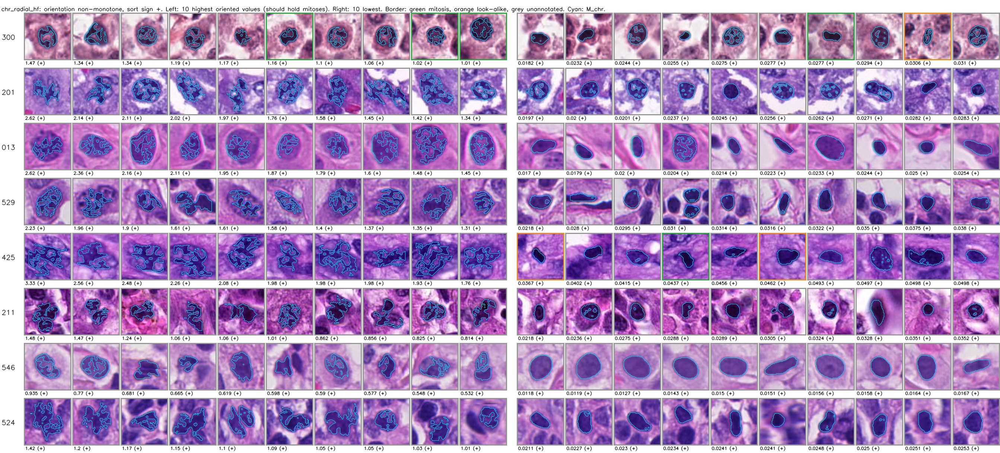

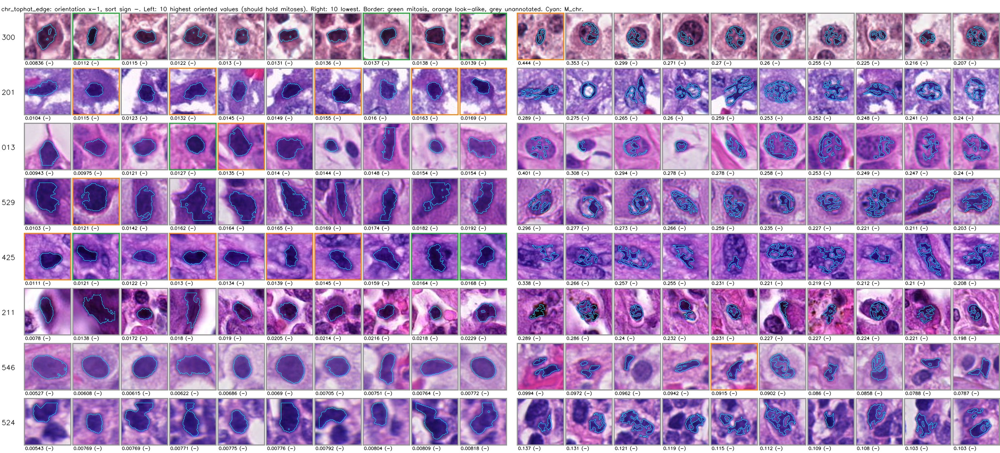

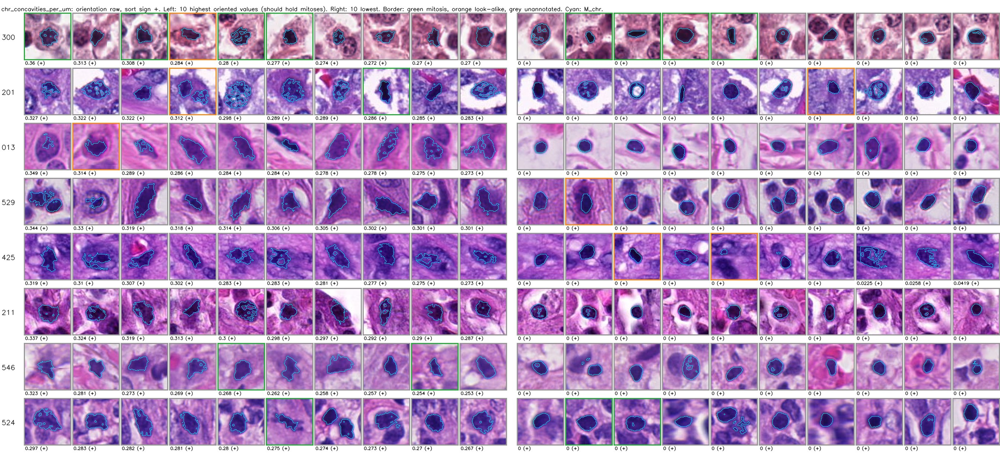

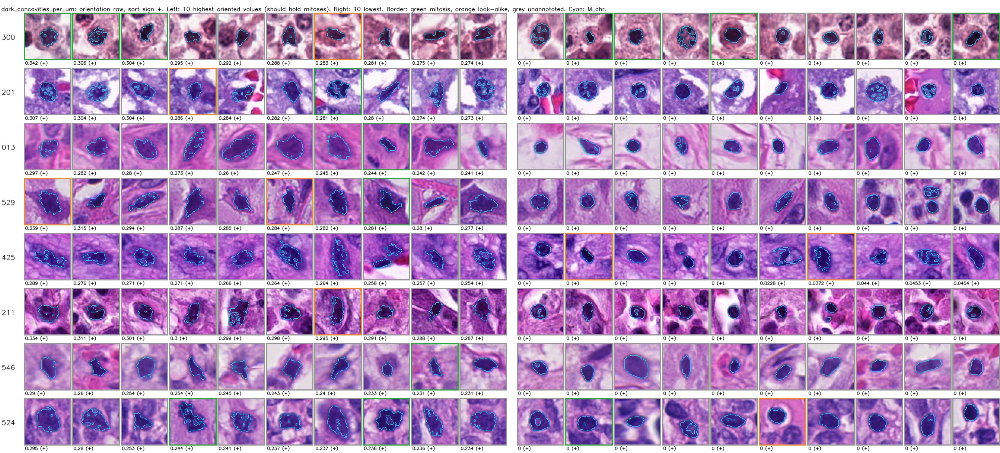

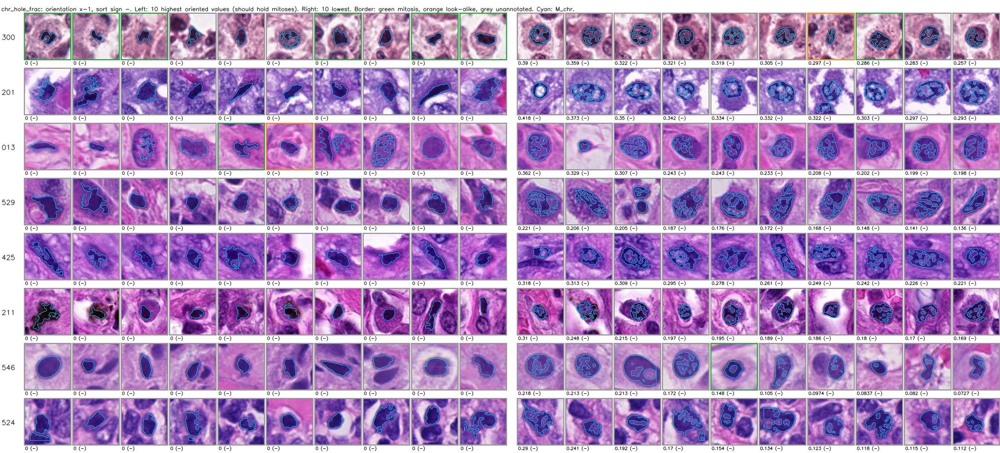

...

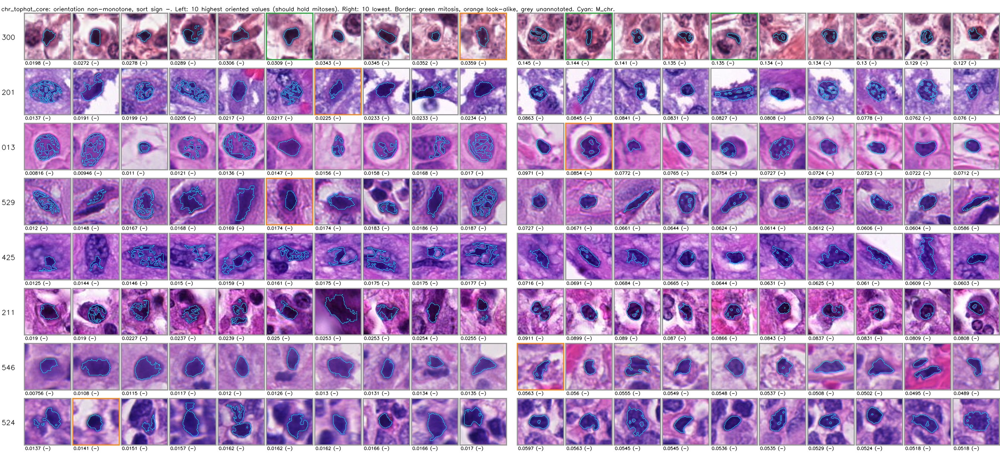

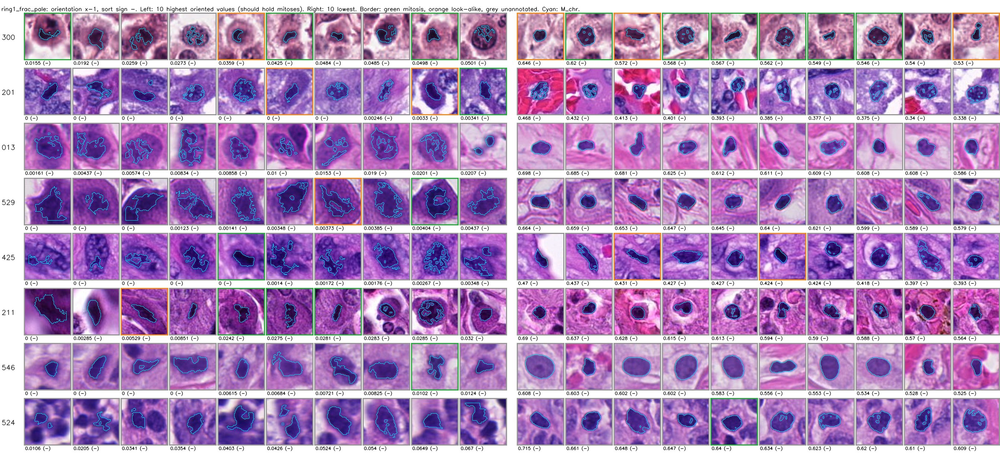

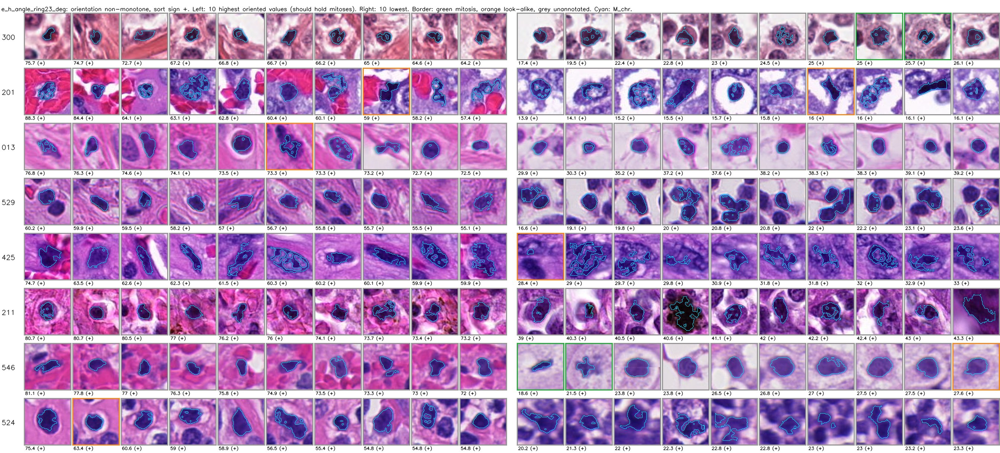

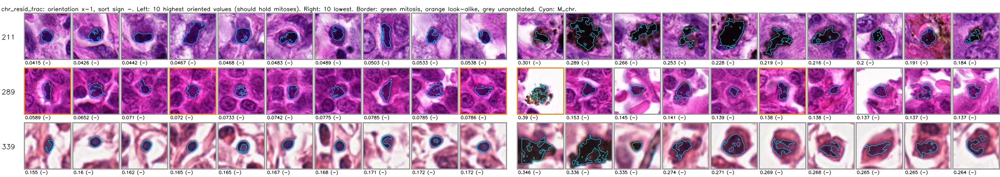

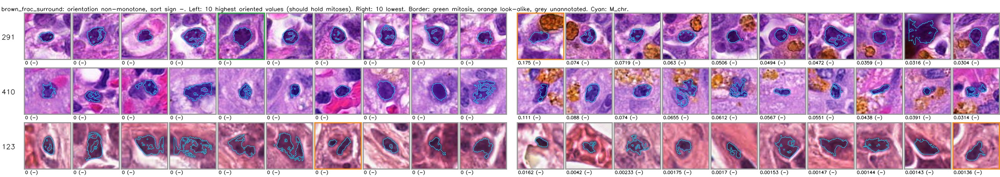

In [23]:
TILE_GAP, CAP_H, LABEL_W, MID_GAP, HEAD_H = 2, 16, 64, 26, 34


def caption_strip(text, width, height=CAP_H, scale=0.38):
    """
        A white strip with one line of black text.

        text (str): the caption (ASCII).
        width (int): the strip width.
        height (int): the strip height.
        scale (float): the cv2 font scale.

        Returns np.ndarray: the uint8 RGB strip.
    """
    s = np.full((height, width, 3), 255, np.uint8)
    cv2.putText(s, text, (3, height - 5), cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), 1, cv2.LINE_AA)
    return s


def montage_tile(win, bucket, caption):
    """
        One montage tile: the 61 px RGB window at 2x, M_chr outlined, a bucket-coloured border and a caption.

        win (dict): rgb61 and m_chr51 from W.montage_windows.
        bucket (str): the location's bucket.
        caption (str): the caption text.

        Returns np.ndarray: the uint8 RGB tile.
    """
    t = cv2.resize(win['rgb61'], None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST).copy()
    if win['m_chr51'] is not None:
        m61 = np.zeros((61, 61), np.uint8)
        m61[5:56, 5:56] = win['m_chr51'].astype(np.uint8) * 255
        cs, _ = cv2.findContours(cv2.resize(m61, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(t, cs, -1, OUTLINE_RGB, 1)
    t = cv2.copyMakeBorder(t, 3, 3, 3, 3, cv2.BORDER_CONSTANT, value=BUCKET_RGB[bucket])
    return np.vstack([t, caption_strip(caption, t.shape[1])])


def hstack_tiles(tiles, n, tile_shape):
    """
        n tiles side by side with gaps, padding with blanks when fewer exist.

        tiles (list): the tiles.
        n (int): the number of slots.
        tile_shape (tuple): one tile's shape.

        Returns np.ndarray: the strip.
    """
    blank = np.full(tile_shape, 255, np.uint8)
    gap = np.full((tile_shape[0], TILE_GAP, 3), 255, np.uint8)
    parts = []
    for i in range(n):
        parts += [tiles[i] if i < len(tiles) else blank, gap]
    return np.hstack(parts[:-1])


def show_and_save(img, name):
    """
        Embed a mosaic in the notebook as JPEG and save its left and right halves as PNG in VIEW_DIR for the agent's own look.

        img (np.ndarray): the RGB mosaic.
        name (str): a file stem.

        Returns None.
    """
    ok, buf = cv2.imencode('.jpg', cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 88])
    display(Image(data=buf.tobytes(), format='jpeg'))
    os.makedirs(VIEW_DIR, exist_ok=True)
    half = LABEL_W + MONTAGE_K * (TILE_W + TILE_GAP)
    cv2.imwrite(os.path.join(VIEW_DIR, f'{name}{SUFFIX}_left.png'), cv2.cvtColor(img[:, :half], cv2.COLOR_RGB2BGR))
    cv2.imwrite(os.path.join(VIEW_DIR, f'{name}{SUFFIX}_right.png'), cv2.cvtColor(np.hstack([img[:, :LABEL_W], img[:, half + MID_GAP:]]), cv2.COLOR_RGB2BGR))


def row_tiles(picks, f, col, sign):
    """
        The captioned tiles of one ROI's picks.

        picks (list): the picked location rows.
        f (str): the ROI file name.
        col (str): the montage column.
        sign (int): the sort sign.

        Returns list: the tiles.
    """
    return [montage_tile(WINDOWS[f][(p['cx'], p['cy'])], p['bucket_maj'], f"{p[col]:.3g} ({'+' if sign > 0 else '-'})") for p in picks]


TILE_W, TILE_H = 61 * 2 + 6, 61 * 2 + 6 + CAP_H
for col in MONTAGE_COLS:
    sign = montage_sign(col)
    o = 'raw (diagnostic)' if col == 'chr_edge_sharpness_per_um' else V300.loc[col, 'orientation_recommended']
    rows = []
    for rid in MONTAGE_ROIS_PIGMENT.get(col, MONTAGE_ROIS):
        f = f'{rid}.tiff'
        if (col, rid) not in PICKS:
            continue
        top, bottom = PICKS[(col, rid)]
        label = np.full((TILE_H, LABEL_W, 3), 255, np.uint8)
        cv2.putText(label, rid, (4, TILE_H // 2), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
        rows.append(np.hstack([label, hstack_tiles(row_tiles(top, f, col, sign), MONTAGE_K, (TILE_H, TILE_W, 3)), np.full((TILE_H, MID_GAP, 3), 255, np.uint8), hstack_tiles(row_tiles(bottom, f, col, sign), MONTAGE_K, (TILE_H, TILE_W, 3))]))
        rows.append(np.full((4, rows[-1].shape[1], 3), 255, np.uint8))
    if not rows:
        print(f'{col}: no montage ROI in this run')
        continue
    body = np.vstack(rows)
    head = caption_strip(f'{col}: orientation {o}, sort sign {"+" if sign > 0 else "-"}. Left: 10 highest oriented values (should hold mitoses). Right: 10 lowest. Border: green mitosis, orange look-alike, grey unannotated. Cyan: M_chr.', body.shape[1], HEAD_H, 0.5)
    show_and_save(np.vstack([head, body]), f'montage_{col}')

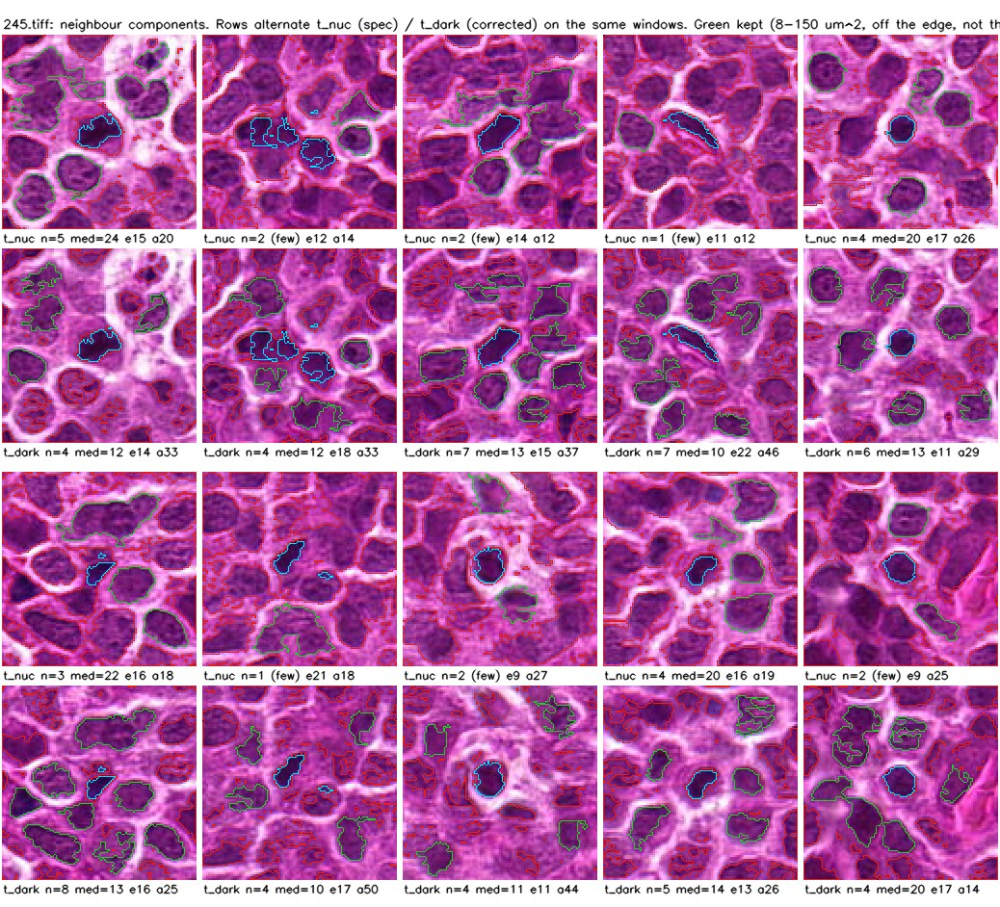

245.tiff [{'cx': 2167.0, 'cy': 2329.0, 'spec_n': 5, 'corrected_n': 4, 'corrected_med': 12.3}, {'cx': 5886.0, 'cy': 4877.0, 'spec_n': 2, 'corrected_n': 4, 'corrected_med': 12.3}, {'cx': 4632.0, 'cy': 4136.0, 'spec_n': 2, 'corrected_n': 7, 'corrected_med': 12.7}, {'cx': 2234.0, 'cy': 596.0, 'spec_n': 1, 'corrected_n': 7, 'corrected_med': 10.1}, {'cx': 3648.0, 'cy': 4758.0, 'spec_n': 4, 'corrected_n': 6, 'corrected_med': 13.4}, {'cx': 4484.0, 'cy': 3596.0, 'spec_n': 3, 'corrected_n': 8, 'corrected_med': 12.9}, {'cx': 6090.0, 'cy': 2029.0, 'spec_n': 1, 'corrected_n': 4, 'corrected_med': 10.2}, {'cx': 2807.0, 'cy': 1362.0, 'spec_n': 2, 'corrected_n': 4, 'corrected_med': 11.0}, {'cx': 3405.0, 'cy': 1100.0, 'spec_n': 4, 'corrected_n': 5, 'corrected_med': 13.6}, {'cx': 3922.0, 'cy': 1619.0, 'spec_n': 2, 'corrected_n': 4, 'corrected_med': 20.3}]


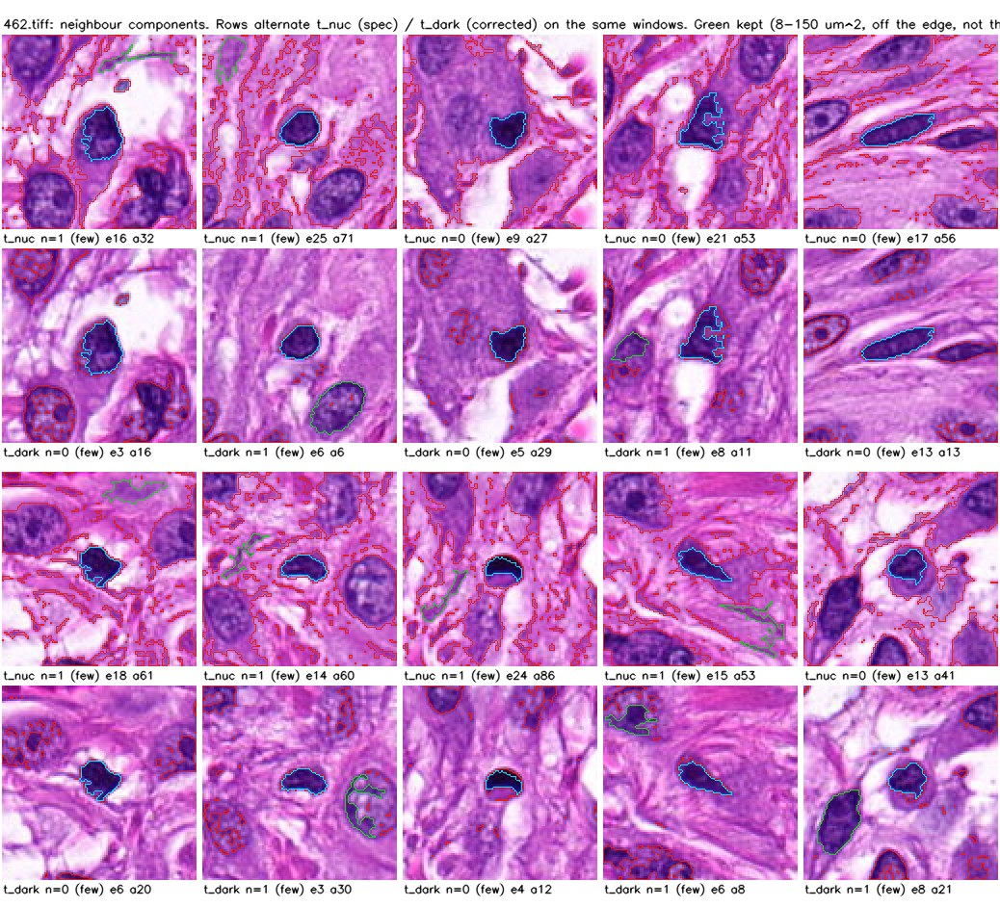

462.tiff [{'cx': 5806.0, 'cy': 2105.0, 'spec_n': 1, 'corrected_n': 0, 'corrected_med': nan}, {'cx': 4666.0, 'cy': 2460.0, 'spec_n': 1, 'corrected_n': 1, 'corrected_med': nan}, {'cx': 4063.0, 'cy': 1116.0, 'spec_n': 0, 'corrected_n': 0, 'corrected_med': nan}, {'cx': 6395.0, 'cy': 2834.0, 'spec_n': 0, 'corrected_n': 1, 'corrected_med': nan}, {'cx': 773.0, 'cy': 1689.0, 'spec_n': 0, 'corrected_n': 0, 'corrected_med': nan}, {'cx': 4508.0, 'cy': 51.0, 'spec_n': 1, 'corrected_n': 0, 'corrected_med': nan}, {'cx': 5838.0, 'cy': 586.0, 'spec_n': 1, 'corrected_n': 1, 'corrected_med': nan}, {'cx': 6179.0, 'cy': 2717.0, 'spec_n': 1, 'corrected_n': 0, 'corrected_med': nan}, {'cx': 5574.0, 'cy': 4262.0, 'spec_n': 1, 'corrected_n': 1, 'corrected_med': nan}, {'cx': 4077.0, 'cy': 1235.0, 'spec_n': 0, 'corrected_n': 1, 'corrected_med': nan}]


In [24]:
# the neighbour check (5.8 d): the same 10 random accepted candidates on 245 and 462, the spec's t_nuc components (top row of each pair) and the corrected t_dark components (bottom row); kept in green, dropped in red, M_chr in cyan
def nbr_tile(it, which):
    """
        One neighbour-check tile: the 101 px RGB window at 2x with one definition's components outlined.

        it (dict): one W.neighbour_check item.
        which (str): 'spec' (t_nuc) or 'corrected' (t_dark).

        Returns np.ndarray: the captioned tile.
    """
    d = it[which]
    t = cv2.resize(it['rgb101'], None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST).copy()
    for k, st in d['status'].items():
        m = cv2.resize((d['lab'] == k).astype(np.uint8) * 255, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
        cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(t, cs, -1, (40, 200, 40) if st == 'kept' else (230, 30, 30), 1)
    cs, _ = cv2.findContours(cv2.resize(it['m_chr_101'].astype(np.uint8) * 255, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(t, cs, -1, OUTLINE_RGB, 1)
    n_st = pd.Series(d['status']).value_counts().to_dict() if d['status'] else {}
    med = d['cols']['nbr_nuc_area_med_um2']
    cap = f"{'t_nuc' if which == 'spec' else 't_dark'} n={d['cols']['nbr_n']} " + (f'med={med:.0f}' if np.isfinite(med) else '(few)') + f" e{n_st.get('edge', 0)} a{n_st.get('area', 0)}"
    return np.vstack([cv2.copyMakeBorder(t, 2, 2, 2, 2, cv2.BORDER_CONSTANT, value=(255, 255, 255)), caption_strip(cap, t.shape[1] + 4)])


for f, items in NBR_OUT.items():
    strips = []
    for half in (items[:5], items[5:]):
        for which in ('spec', 'corrected'):
            tiles = [nbr_tile(it, which) for it in half]
            strips.append(hstack_tiles(tiles, 5, tiles[0].shape))
        strips.append(np.full((10, strips[-1].shape[1], 3), 255, np.uint8))
    grid = np.vstack(strips)
    head = caption_strip(f'{f}: neighbour components. Rows alternate t_nuc (spec) / t_dark (corrected) on the same windows. Green kept (8-150 um^2, off the edge, not the core); red dropped; cyan M_chr. e / a: dropped at the edge / by area.', grid.shape[1], HEAD_H, 0.42)
    img = np.vstack([head, grid])
    ok, buf = cv2.imencode('.jpg', cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 88])
    display(Image(data=buf.tobytes(), format='jpeg'))
    cv2.imwrite(os.path.join(VIEW_DIR, f'nbrcheck_{f.split(".")[0]}{SUFFIX}.png'), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    print(f, [dict(cx=it['cx'], cy=it['cy'], spec_n=it['spec']['cols']['nbr_n'], corrected_n=it['corrected']['cols']['nbr_n'], corrected_med=round(it['corrected']['cols']['nbr_nuc_area_med_um2'], 1)) for it in items])

## Outputs, all written at the end (spec Section 8)

In [25]:
def jsonable(v):
    """
        A JSON-serialisable copy of a constant.

        v (object): the value.

        Returns object: lists for arrays and tuples, plain numbers otherwise.
    """
    if isinstance(v, np.ndarray):
        return v.tolist()
    if isinstance(v, (tuple, list)):
        return [jsonable(x) for x in v]
    if isinstance(v, dict):
        return {str(k): jsonable(x) for k, x in v.items()}
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    return v


FEATURE_CONSTANTS = ('MIN_PIECE_PX', 'CONCAVITY_MIN_UM', 'RADIAL_POINTS', 'RADIAL_BAND', 'PAIR_MIN_UM2', 'PAIR_MIN_RATIO', 'PAIR_MAX_UM', 'PAIR_ELONG_MIN', 'WIN101', 'WIN61', 'NS_MIN_PX', 'GLASS_GRAY', 'BROWN_R_MINUS_B', 'BROWN_G_MINUS_B', 'BROWN_GRAY_MAX', 'RESID_DILATE_PX', 'NS_LO', 'NS_HI', 'TOPHAT_R_UM', 'TOPHAT_RING_UM', 'TOPHAT_CORE_UM', 'EDGE_MIN_STEP', 'NBR_MIN_UM2', 'NBR_MAX_UM2', 'NBR_MIN_N', 'RESID_NORMAL')
assert DIRECTIONS.to_csv(index=False, lineterminator='\n').encode('utf-8') == DIRECTIONS_BYTES, 'the frozen directions literal changed'
SPEC = dict(spec='CANDIDATE_FEATURE_EXTRACTION_PROMPT_V2.md', notebook='candidate_features_a3_top300.ipynb', worker='candidate_features_a3_top300_worker.py', worker_sha256_12=INPUT_SHA['worker'], smoke=SMOKE_ROIS is not None, smoke_rois=SMOKE_ROIS or [], refine_sha1=W.REFINE_SHA1, refine_constants={k: jsonable(getattr(W, k)) for k in W.REFINE_CONSTANTS}, search_constants={k: jsonable(getattr(W, k)) for k in W.SEARCH_CONSTANTS}, production=dict(MAX_PEAKS=prod.MAX_PEAKS, DEEP_FLOOR_Z=prod.DEEP_FLOOR_Z, PEAK_MIN_DISTANCE=prod.PEAK_MIN_DISTANCE, TM_METHOD=int(prod.TM_METHOD), OD_WINDOW=prod.OD_WINDOW, MIDOG_RADIUS_UM=ev.MIDOG_RADIUS_UM), deep=dict(DEPTH=W.DEPTH, UNCAPPED=W.UNCAPPED), feature_constants={k: jsonable(getattr(W, k)) for k in FEATURE_CONSTANTS}, validity=dict(N_OD_STRATA=N_OD_STRATA, N_AREA_STRATA=N_AREA_STRATA, HOLE_SPLIT=HOLE_SPLIT, CONSISTENT_ROI_SHARE='2/3', CONSISTENT_DOMAINS=CONSISTENT_DOMAINS, TB_K=TB_K, TB_MIN_ROWS=TB_MIN_ROWS, AREA_COLS=list(AREA_COLS)), gates=dict(TOL_FLOAT=TOL_FLOAT, GATE_C_MAX_SHARE=GATE_C_MAX_SHARE), montage=dict(MONTAGE_ROIS=list(MONTAGE_ROIS), MONTAGE_ROIS_PIGMENT={k: list(v) for k, v in MONTAGE_ROIS_PIGMENT.items()}, MONTAGE_K=MONTAGE_K, MONTAGE_SEP_UM=MONTAGE_SEP_UM, NBR_CHECK_ROIS=list(NBR_CHECK_ROIS), NBR_CHECK_N=NBR_CHECK_N, NBR_CHECK_SEED=NBR_CHECK_SEED), roi_group_failing9=list(ROI_GROUP_FAILING), scanner_map=SCANNER_MAP, directions_sha1=DIRECTIONS_SHA1, directions_amendment_sha1=DIRECTIONS_AMENDMENT_SHA1, neighbour_threshold=W.NBR_THRESHOLD, columns=dict(features=list(W.FEATURES), diagnostics=list(W.DIAGNOSTICS), spec=list(W.SPEC_COLUMNS), reasons=list(W.REASONS)))
CLICKS_OUT = CLK.merge(CLICKS, on=['file_name', 'seed_index'], how='left', validate='one_to_one')[['subset', 'domain', 'file_name', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy', 'tcx', 'tcy', 'bs', 'b', 'threshold', 'n_peaks', 'n_nms_prefix', 'n_detections_recorded', 't_search_s', 't_nuc', 't_dark', 'mpp', 'radius_px', 'score_peak_100', 'score_peak_101', 'tpl_sha1', 'mass_weight', 'degenerate']]
OUT_VALIDITY = [c for c in VALIDITY.columns if c not in ('roi_auc', 'domain_auc')]
written = {}
for name, df in (('candidates', C), ('clicks', CLICKS_OUT), ('directions', DIRECTIONS_OUT), ('validity', VALIDITY[OUT_VALIDITY]), ('validity_depth300', VALIDITY_300[[c for c in VALIDITY_300.columns if c not in ('roi_auc', 'domain_auc')]]), ('redundancy', REDUNDANCY.rename_axis('column').reset_index()), ('synthetic_tests', SYN_DF), ('adversarial_log', pd.DataFrame(list(ADV.values()))[['item', 'concern', 'test', 'result', 'action']])):
    if name == 'directions':
        with open(OUT[name], 'wb') as fh:
            fh.write(DIRECTIONS_OUT.to_csv(index=False, lineterminator='\n').encode('utf-8'))
    else:
        df.to_csv(OUT[name], index=False)
    written[name] = len(df)
with open(OUT['spec_json'], 'w') as fh:
    json.dump(SPEC, fh, sort_keys=True, indent=1)
    fh.write('\n')
print('written:', written)
print(f"spec JSON SHA-1 {hashlib.sha1(open(OUT['spec_json'], 'rb').read()).hexdigest()}; directions.csv SHA-1 {DIRECTIONS_SHA1} (file {hashlib.sha1(open(OUT['directions'], 'rb').read()).hexdigest()})")
print(f'notebook total {(time.time() - NB_T0) / 60:.1f} min')

written: {'candidates': 88200, 'clicks': 294, 'directions': 36, 'validity': 27, 'validity_depth300': 27, 'redundancy': 25, 'synthetic_tests': 955, 'adversarial_log': 19}
spec JSON SHA-1 546502d4571a47379a7871168cb5423b556fb9cb; directions.csv SHA-1 620d50f307995984eed9a9c387a047b79abe5b94 (file 63c00a7b484ca36878441ee24dc5a0c1b94e14df)
notebook total 2.8 min


## Reading

*Written after the full run (2.8 min on 4 workers) from the outputs above and the montages. The full write-up, with the tables, is `candidate_features_a3_top300_findings.md` next to this notebook. Everything is in-sample on the 49 ROIs. For the five spike columns the pool rows were seen before freezing, so only the beyond-pool AUCs are unseen.*

**Gates.**
- **A:** the refinement SHA-1 is `21c43a20`.
- **B:** 293 clicks exact and 1 near-tie (`242.tiff` click 1, rank 91: a peak one pixel over, 1.2e-7 apart; labels equal).
- **C:** 17,735 shared locations, 0 mismatches.
- **`directions.csv`:** SHA-1 `620d50f3…`, the same in the smoke run and the full run.

### Per-feature verdicts (does it measure what it claims?)

- **One cause behind the boundary family** (a by-eye montage reading, not measured). On pale, open-chromatin nuclei, `M_chr` looks like a branching chromatin network, not a dense core. The boundary columns appear to measure partly "reticulum against solid core".
- **`chr_tophat_edge`: no.** It measures how thin or reticulated `M_chr` is: pale-nucleus chromatin networks, fragments and pigment. Mitoses sit at the low end (x-1, 0.389 at depth 300, 0.384 within size), opposite to its +1 hypothesis.
- **`chr_radial_hf`: no, beyond the pool.** The unblinded pool AUC of 0.561 falls to 0.502 at depth 300 and 0.484 beyond the pool. Its high end is chromatin networks.
- **`chr_solidity`: yes**, with the reticulum caveat. x-1 holds beyond the pool (0.410).
- **`chr_concavities_per_um`: yes.** Ragged outlines against smooth ones. raw, 0.605, holding beyond the pool (0.603).
- **`dark_concavities_per_um`: yes.** It has the highest boundary AUC (0.631, 0.670 beyond darkness, 0.627 beyond the pool). On uncut rows, as Section 5.2 requires for the comparison and computed after the run, it leads `chr_concavities_per_um` by +0.020 in the pool, +0.017 at depth 300 and +0.021 beyond the pool (0.628 against 0.607). On all rows the lead is +0.024 to +0.030. No CI was computed.
- **`chr_hole_frac`: yes**, enclosed holes (reticula and rims). x-1, 0.386.
- **`chr_elongation`: yes.** raw, 0.644.
- **`chr_area_um2`: yes.** Mitoses have smaller cores (x-1, 0.429).
- **`h_chr_mean`: yes.** 0.835, and 0.677 within `od` strata.
- **`h_chr_lap`: partly.** It separates (x-1, 0.362, 0.354 within size), but its high end is thin or small masks and reticula, not texture alone.
- **`chr_tophat_core`: unclear.** Its low end mixes networks with homogeneous cores. No consistent relation.
- **`ring_peak_prominence`: no.** It measures dark mass within 3 µm (crowding, clumps inside nuclei), not an envelope. x-1.
- **`ring1_frac_above_tnuc`: yes.** raw, 0.641.
- **`ring1_frac_pale`: yes.** Halos and pale cytoplasm. ROI-dependent; x-1 at depth 300.
- **`white_frac_gray215_61`: yes.** x-1, 0.401.
- **`e_h_angle_ring23_deg`: no.** It reads red cells and stroma around the candidate, not the cell's cytoplasm, and has no signal (0.519).
- **`brown_frac_surround`: yes, on pigment ROIs.** Golden-brown granules on 291 and 410, and the red-cell exclusion holds on 123. About 0.50 pooled, because 97.7 % of rows are 0.
- **`dark_area_frac_101`: yes, crowding.** 0.464 within click, but 0.374 beyond darkness.
- **`chr_resid_frac`: yes at the top, which is pigment** (211, 289, 339). The signal extends beyond pigment (other40 0.36, Aperio 0.165), and its support is label-dependent. The spec's "mitoses higher on non-pigment ROIs" anchor used a different population, so it is not like-for-like.
- **`chr_area_over_nbr`:** the spec's `t_nuc` version is defective. The `t_dark` version measures what it claims, but is NaN on 87 % of rows.
- **Pair columns:** they pass the pair test. Marginal AUCs are near 0.5, except `pair_sep_um` (raw, 0.578).

### Montage judgements (one sentence each)

- **`chr_concavities_per_um`:** the high end is notched, angular cores, mostly interphase with a few mitoses; the low end is smooth round cores at 0. It shows outline irregularity, as claimed.
- **`dark_concavities_per_um`:** the same contrast on the lower-threshold mask, with slightly more mitoses at the high end. As claimed.
- **`chr_radial_hf`:** the high end is branching chromatin networks of pale nuclei, not spiky figures; the low end is smooth compact cores. It does not look like spikes.
- **`chr_solidity`:** the low end is reticulated networks and a few ragged mitoses; the high end is smooth round cores. Convexity, as claimed, but dominated by reticula.
- **`chr_tophat_edge`:** the high raw end is thin networks, fragments and pigment; the low raw end is solid compact cores including mitoses. It does not look like fine arms on a core.
- **`chr_hole_frac`:** the high end is rings and reticula enclosing pale holes; the low end is solid cores. As claimed.
- **`ring_peak_prominence`:** the high end is a candidate with a dark neighbour 2–3 µm away; the low end is isolated objects. Crowding, not an envelope.
- **`chr_edge_sharpness_per_um`:** the high end is chromatin clumps inside nuclei (a small ring-1 step); the low end is merged and blurred masses. Not clearly edge crispness.
- **`h_chr_lap`:** the low end is large homogeneous dark cores, including mitoses; the high end is thin or small masks and reticula. Texture plus thinness.
- **`chr_tophat_core`:** the high end is compact cores with internal dark granules; the low end mixes networks with homogeneous cores. Ambiguous.
- **`ring1_frac_pale`:** the high end is dark cores in a pale perinuclear rim, including mitoses on 300; the low end is clumps inside nucleoplasm. As claimed.
- **`e_h_angle_ring23_deg`:** the high end is red cells and pink stroma around the candidate; the low end is bluish crowded surround. It is the neighbourhood's eosin, not the cell's cytoplasm.
- **`chr_resid_frac`:** the high end is black and brown pigment on 211, 289 and 339, then reddish-tinted nuclei; the low end is ordinary blue nuclei. As claimed at the top.
- **`brown_frac_surround`:** the high end is golden-brown granules beside the candidate on 291 and 410, with near-zero red-cell values on 123. As claimed; no threshold changed.
- **Neighbour check (245, 462):** at `t_nuc` the kept components on 462 are stroma strands, so the definition is defective. At `t_dark` they are nuclei, sometimes partial; on 462, 10 of 10 windows still have fewer than 3.

### Adversarial log

19 rows, in full in `adversarial_log.csv`.
- **unblinded_2026_10_09:** stated wherever the five columns are reported.
- **worker_module:** the code lives in `candidate_features_a3_top300_worker.py`, extracted verbatim with ast.
- **view_dir:** montage copies go to the session scratchpad.
- **Readings:** pair_anchor_tie, dark_piece_rule, matched_ann_id_convention, debris_index (k = 0..n_f−2).
- **elongation_degenerate:** 0 rows.
- **gate_b_classifier:** the adjacent-pixel near-tie class was added after a halt.
- **clipped_test_draw:** reported, not a failure.
- **ordering_criteria:** explicit thresholds for "clearly" and "far".
- **top300_only:** NMS on a score-sorted prefix; identical rows.
- **nbr_t_nuc_defect:** `t_dark` adopted, spec_ columns kept.
- **dev_looks:** none needed.
- **Additions:** nonmonotone_descriptor, beyond_pool_auc, tb_ties (tie-averaged counts).
- **montage_bucket, montage_embed:** logged.
- **Added after the run:**
  - montage picks break ties by `cx, cy`, so the tied (zero) ends of tie-heavy columns show the leftmost locations, not a sample;
  - the uncut-row concavity comparison above.

### What in the spec I changed, and why

1. **The search reads only as deep as the top 300 needs**, at the user's instruction. The output is identical; `n_detections_deep` is dropped.
2. **Gate B gained an adjacent-pixel near-tie class.** It is the spec's own rule; the spec's two examples didn't cover a one-pixel peak move.
3. **The neighbour columns use `t_dark`**, under the defect rule. The `t_nuc` versions are kept as `spec_` columns.
4. **Tie-averaged top/bottom counts were added**, because the spec's `cand_rank` tie-break inflated brown_frac 1730/409 against 788/749.
5. **Also added:** the beyond-pool AUCs and the absdev descriptor.
6. **Readings and mechanics:** as in the log.

### What I could not check

- **Hole split:** `auc_hole_gt03` is undefined, because no click has both classes with hole > 0.3.
- **Full post-NMS count:** not computed.
- **Out-of-sample orientation:** none.
- **Neighbour window size:** left to the user.
- **Pathologist review:** none. The montage readings are by eye.